In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Fixed random seed for reproducibility
RANDOM_SEED = 42

np.random.seed(RANDOM_SEED)

In [3]:
# Number of samples in each class
samples_per_class = 500

# Mean and covariance for Class 0
mean_class_0 = [-3, -2]
cov_class_0 = [
    [0.8, 0],
    [0, 0.8]
]

# Mean and covariance for Class 1
mean_class_1 = [3, -2]
cov_class_1 = [
    [0.7, 0],
    [0, 0.7]
]

# Mean and covariance for Class 2
mean_class_2 = [0, 3]
cov_class_2 = [
    [0.9, 0],
    [0, 0.9]
]

# Generate Gaussian data for each class
X_class_0 = np.random.multivariate_normal(
    mean_class_0,
    cov_class_0,
    samples_per_class
)

X_class_1 = np.random.multivariate_normal(
    mean_class_1,
    cov_class_1,
    samples_per_class
)

X_class_2 = np.random.multivariate_normal(
    mean_class_2,
    cov_class_2,
    samples_per_class
)

# Combine all classes into one dataset
X_gaussian = np.vstack([
    X_class_0,
    X_class_1,
    X_class_2
])

# Create class labels
y_gaussian = np.array(
    [0] * samples_per_class +
    [1] * samples_per_class +
    [2] * samples_per_class
)

print("Shape of input data:", X_gaussian.shape)
print("Shape of labels:", y_gaussian.shape)

Shape of input data: (1500, 2)
Shape of labels: (1500,)


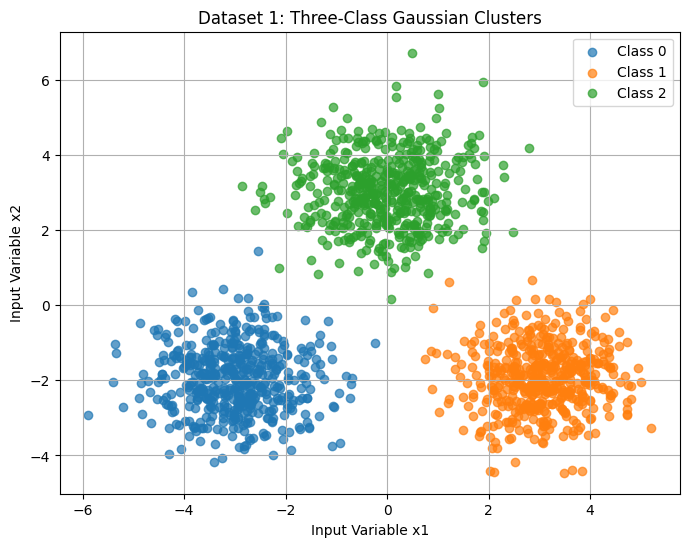

In [4]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_class_0[:, 0],
    X_class_0[:, 1],
    label="Class 0",
    alpha=0.7
)

plt.scatter(
    X_class_1[:, 0],
    X_class_1[:, 1],
    label="Class 1",
    alpha=0.7
)

plt.scatter(
    X_class_2[:, 0],
    X_class_2[:, 1],
    label="Class 2",
    alpha=0.7
)

plt.xlabel("Input Variable x1")
plt.ylabel("Input Variable x2")

plt.title("Dataset 1: Three-Class Gaussian Clusters")

plt.legend()
plt.grid(True)

plt.show()

In [5]:
def split_data_per_class(
    X,
    y,
    train_ratio=0.60,
    validation_ratio=0.20,
    test_ratio=0.20,
    random_seed=42
):

    np.random.seed(random_seed)

    X_train_list = []
    X_val_list = []
    X_test_list = []

    y_train_list = []
    y_val_list = []
    y_test_list = []

    # Process each class separately
    for class_label in np.unique(y):

        # Get indices of the current class
        class_indices = np.where(
            y == class_label
        )[0]

        # Shuffle indices
        np.random.shuffle(class_indices)

        # Number of samples
        n_samples = len(class_indices)

        # Calculate split positions
        train_end = int(
            train_ratio * n_samples
        )

        val_end = int(
            (train_ratio + validation_ratio)
            * n_samples
        )

        # Split indices
        train_indices = class_indices[:train_end]

        val_indices = class_indices[
            train_end:val_end
        ]

        test_indices = class_indices[
            val_end:
        ]

        # Store data
        X_train_list.append(
            X[train_indices]
        )

        X_val_list.append(
            X[val_indices]
        )

        X_test_list.append(
            X[test_indices]
        )

        # Store labels
        y_train_list.append(
            y[train_indices]
        )

        y_val_list.append(
            y[val_indices]
        )

        y_test_list.append(
            y[test_indices]
        )

    # Combine data from all classes
    X_train = np.vstack(X_train_list)
    X_val = np.vstack(X_val_list)
    X_test = np.vstack(X_test_list)

    y_train = np.concatenate(y_train_list)
    y_val = np.concatenate(y_val_list)
    y_test = np.concatenate(y_test_list)

    return (
        X_train,
        X_val,
        X_test,
        y_train,
        y_val,
        y_test
    )

In [6]:
(
    X_train_gaussian,
    X_val_gaussian,
    X_test_gaussian,
    y_train_gaussian,
    y_val_gaussian,
    y_test_gaussian
) = split_data_per_class(
    X_gaussian,
    y_gaussian
)

print("Training data shape:", X_train_gaussian.shape)
print("Validation data shape:", X_val_gaussian.shape)
print("Test data shape:", X_test_gaussian.shape)

Training data shape: (900, 2)
Validation data shape: (300, 2)
Test data shape: (300, 2)


In [7]:
# Calculate mean from training data
mean = np.mean(
    X_train_gaussian,
    axis=0
)

# Calculate standard deviation
std = np.std(
    X_train_gaussian,
    axis=0
)

# Normalize training data
X_train_gaussian_normalized = (
    X_train_gaussian - mean
) / std

# Normalize validation data
X_val_gaussian_normalized = (
    X_val_gaussian - mean
) / std

# Normalize test data
X_test_gaussian_normalized = (
    X_test_gaussian - mean
) / std

In [8]:
def one_hot_encode(y, num_classes=3):

    encoded = np.zeros(
        (len(y), num_classes)
    )

    encoded[
        np.arange(len(y)),
        y
    ] = 1

    return encoded

In [9]:
y_train_gaussian_onehot = one_hot_encode(
    y_train_gaussian
)

y_val_gaussian_onehot = one_hot_encode(
    y_val_gaussian
)

y_test_gaussian_onehot = one_hot_encode(
    y_test_gaussian
)

print(
    y_train_gaussian_onehot[:5]
)

[[1. 0. 0.]
 [1. 0. 0.]
 [1. 0. 0.]
 [1. 0. 0.]
 [1. 0. 0.]]


In [10]:
def sigmoid(x):

    x = np.clip(
        x,
        -500,
        500
    )

    return 1 / (
        1 + np.exp(-x)
    )
def sigmoid_derivative(
    sigmoid_output
):

    return (
        sigmoid_output
        * (1 - sigmoid_output)
    )
def squared_error(
    target,
    prediction
):

    return 0.5 * np.sum(
        (target - prediction) ** 2
    )

In [11]:
class FCNN_OneHiddenLayer:

    def __init__(
        self,
        input_size,
        hidden_size,
        output_size,
        random_seed=42
    ):

        np.random.seed(random_seed)

        # Input to hidden layer weights
        self.W1 = (
            np.random.randn(
                input_size,
                hidden_size
            )
            * np.sqrt(
                1 / input_size
            )
        )

        # Hidden layer bias
        self.b1 = np.zeros(
            hidden_size
        )

        # Hidden to output weights
        self.W2 = (
            np.random.randn(
                hidden_size,
                output_size
            )
            * np.sqrt(
                1 / hidden_size
            )
        )

        # Output layer bias
        self.b2 = np.zeros(
            output_size
        )

In [12]:
def forward(
    self,
    x
):

    # Hidden layer
    self.z1 = (
        np.dot(
            x,
            self.W1
        )
        + self.b1
    )

    self.hidden_output = sigmoid(
        self.z1
    )

    # Output layer
    self.z2 = (
        np.dot(
            self.hidden_output,
            self.W2
        )
        + self.b2
    )

    self.output = sigmoid(
        self.z2
    )

    return self.output

In [13]:
def backward(
    self,
    x,
    target,
    learning_rate
):

    # Output layer error
    output_error = (
        self.output - target
    )

    # Output delta
    output_delta = (
        output_error
        * sigmoid_derivative(
            self.output
        )
    )

    # Gradient for W2
    dW2 = np.outer(
        self.hidden_output,
        output_delta
    )

    # Gradient for b2
    db2 = output_delta

    # Hidden layer error
    hidden_error = np.dot(
        self.W2,
        output_delta
    )

    # Hidden layer delta
    hidden_delta = (
        hidden_error
        * sigmoid_derivative(
            self.hidden_output
        )
    )

    # Gradient for W1
    dW1 = np.outer(
        x,
        hidden_delta
    )

    # Gradient for b1
    db1 = hidden_delta

    # Update weights
    self.W2 -= (
        learning_rate
        * dW2
    )

    self.b2 -= (
        learning_rate
        * db2
    )

    self.W1 -= (
        learning_rate
        * dW1
    )

    self.b1 -= (
        learning_rate
        * db1
    )

In [14]:
def train(
    self,
    X_train,
    y_train,
    learning_rate=0.01,
    epochs=200
):

    average_errors = []

    for epoch in range(epochs):

        total_error = 0

        # Shuffle training samples
        indices = np.random.permutation(
            len(X_train)
        )

        for i in indices:

            # One training example
            x = X_train[i]

            # Target
            target = y_train[i]

            # Forward propagation
            prediction = self.forward(
                x
            )

            # Calculate instantaneous error
            error = squared_error(
                target,
                prediction
            )

            total_error += error

            # Backpropagation
            self.backward(
                x,
                target,
                learning_rate
            )

        # Average error of the epoch
        average_error = (
            total_error
            / len(X_train)
        )

        average_errors.append(
            average_error
        )

        # Print progress
        if (
            epoch + 1
        ) % 20 == 0:

            print(
                f"Epoch {epoch + 1}, "
                f"Average Error: "
                f"{average_error:.6f}"
            )

    return average_errors

In [15]:
def train(
    self,
    X_train,
    y_train,
    learning_rate=0.01,
    epochs=200
):

    average_errors = []

    for epoch in range(epochs):

        total_error = 0

        # Shuffle training samples
        indices = np.random.permutation(
            len(X_train)
        )

        for i in indices:

            # One training example
            x = X_train[i]

            # Target
            target = y_train[i]

            # Forward propagation
            prediction = self.forward(
                x
            )

            # Calculate instantaneous error
            error = squared_error(
                target,
                prediction
            )

            total_error += error

            # Backpropagation
            self.backward(
                x,
                target,
                learning_rate
            )

        # Average error of the epoch
        average_error = (
            total_error
            / len(X_train)
        )

        average_errors.append(
            average_error
        )

        # Print progress
        if (
            epoch + 1
        ) % 20 == 0:

            print(
                f"Epoch {epoch + 1}, "
                f"Average Error: "
                f"{average_error:.6f}"
            )

    return average_errors

In [16]:
class FCNN_OneHiddenLayer:

    def __init__(
        self,
        input_size,
        hidden_size,
        output_size,
        random_seed=42
    ):

        np.random.seed(random_seed)

        # Input to hidden layer
        self.W1 = (
            np.random.randn(
                input_size,
                hidden_size
            )
            * np.sqrt(
                1 / input_size
            )
        )

        self.b1 = np.zeros(
            hidden_size
        )

        # Hidden to output layer
        self.W2 = (
            np.random.randn(
                hidden_size,
                output_size
            )
            * np.sqrt(
                1 / hidden_size
            )
        )

        self.b2 = np.zeros(
            output_size
        )


    # Forward propagation
    def forward(
        self,
        x
    ):

        self.z1 = (
            np.dot(
                x,
                self.W1
            )
            + self.b1
        )

        self.hidden_output = sigmoid(
            self.z1
        )

        self.z2 = (
            np.dot(
                self.hidden_output,
                self.W2
            )
            + self.b2
        )

        self.output = sigmoid(
            self.z2
        )

        return self.output


    # Backpropagation
    def backward(
        self,
        x,
        target,
        learning_rate
    ):

        # Output layer
        output_error = (
            self.output
            - target
        )

        output_delta = (
            output_error
            * sigmoid_derivative(
                self.output
            )
        )

        dW2 = np.outer(
            self.hidden_output,
            output_delta
        )

        db2 = output_delta


        # Hidden layer
        hidden_error = np.dot(
            self.W2,
            output_delta
        )

        hidden_delta = (
            hidden_error
            * sigmoid_derivative(
                self.hidden_output
            )
        )

        dW1 = np.outer(
            x,
            hidden_delta
        )

        db1 = hidden_delta


        # Update weights
        self.W2 -= (
            learning_rate
            * dW2
        )

        self.b2 -= (
            learning_rate
            * db2
        )

        self.W1 -= (
            learning_rate
            * dW1
        )

        self.b1 -= (
            learning_rate
            * db1
        )


    # Training using SGD
    def train(
        self,
        X_train,
        y_train,
        learning_rate=0.01,
        epochs=200
    ):

        average_errors = []

        for epoch in range(epochs):

            total_error = 0

            indices = (
                np.random.permutation(
                    len(X_train)
                )
            )

            for i in indices:

                x = X_train[i]

                target = y_train[i]

                prediction = self.forward(
                    x
                )

                error = squared_error(
                    target,
                    prediction
                )

                total_error += error

                self.backward(
                    x,
                    target,
                    learning_rate
                )

            average_error = (
                total_error
                / len(X_train)
            )

            average_errors.append(
                average_error
            )

            if (
                epoch + 1
            ) % 20 == 0:

                print(
                    f"Epoch {epoch + 1}, "
                    f"Average Error: "
                    f"{average_error:.6f}"
                )

        return average_errors


    # Prediction
    def predict(
        self,
        X
    ):

        predictions = []

        for x in X:

            output = self.forward(
                x
            )

            predicted_class = np.argmax(
                output
            )

            predictions.append(
                predicted_class
            )

        return np.array(
            predictions
        )

In [17]:
hidden_node_options = [
    3,
    5,
    8,
    10
]

learning_rate = 0.01

epochs = 200

gaussian_results = []

trained_gaussian_models = {}
gaussian_histories = {}

In [18]:
for hidden_nodes in hidden_node_options:

    print(
        "\n"
        + "=" * 50
    )

    print(
        f"Training architecture: "
        f"2 -> {hidden_nodes} -> 3"
    )

    model = FCNN_OneHiddenLayer(
        input_size=2,
        hidden_size=hidden_nodes,
        output_size=3,
        random_seed=42
    )

    history = model.train(
        X_train_gaussian_normalized,
        y_train_gaussian_onehot,
        learning_rate=learning_rate,
        epochs=epochs
    )

    # Validation prediction
    y_val_pred = model.predict(
        X_val_gaussian_normalized
    )

    # Validation accuracy
    validation_accuracy = np.mean(
        y_val_pred
        == y_val_gaussian
    )

    gaussian_results.append({

        "Architecture":
            f"2-{hidden_nodes}-3",

        "Hidden Nodes":
            hidden_nodes,

        "Validation Accuracy":
            validation_accuracy,

        "Final Average Error":
            history[-1]

    })

    trained_gaussian_models[
        hidden_nodes
    ] = model

    gaussian_histories[
        hidden_nodes
    ] = history


Training architecture: 2 -> 3 -> 3
Epoch 20, Average Error: 0.087173
Epoch 40, Average Error: 0.028909
Epoch 60, Average Error: 0.017155
Epoch 80, Average Error: 0.012422
Epoch 100, Average Error: 0.009919
Epoch 120, Average Error: 0.008387
Epoch 140, Average Error: 0.007359
Epoch 160, Average Error: 0.006623
Epoch 180, Average Error: 0.006071
Epoch 200, Average Error: 0.005642

Training architecture: 2 -> 5 -> 3
Epoch 20, Average Error: 0.034587
Epoch 40, Average Error: 0.014044
Epoch 60, Average Error: 0.009138
Epoch 80, Average Error: 0.007015
Epoch 100, Average Error: 0.005838
Epoch 120, Average Error: 0.005091
Epoch 140, Average Error: 0.004575
Epoch 160, Average Error: 0.004196
Epoch 180, Average Error: 0.003906
Epoch 200, Average Error: 0.003676

Training architecture: 2 -> 8 -> 3
Epoch 20, Average Error: 0.028057
Epoch 40, Average Error: 0.012490
Epoch 60, Average Error: 0.008479
Epoch 80, Average Error: 0.006674
Epoch 100, Average Error: 0.005652
Epoch 120, Average Error: 0.0

In [19]:
gaussian_results_df = pd.DataFrame(
    gaussian_results
)

gaussian_results_df = (
    gaussian_results_df
    .sort_values(
        by="Validation Accuracy",
        ascending=False
    )
)

display(
    gaussian_results_df
)

,Architecture,Hidden Nodes,Validation Accuracy,Final Average Error
0,2-3-3,3,1.0,0.005642
1,2-5-3,5,1.0,0.003676
2,2-8-3,8,1.0,0.003732
3,2-10-3,10,1.0,0.003485


In [25]:
# ==========================================
# SELECT THE BEST GAUSSIAN ARCHITECTURE
# ==========================================

# Find the highest validation accuracy
highest_validation_accuracy = (
    gaussian_results_df[
        "Validation Accuracy"
    ].max()
)


# Keep only architectures having
# the highest validation accuracy
candidate_models = gaussian_results_df[
    gaussian_results_df[
        "Validation Accuracy"
    ] == highest_validation_accuracy
]


# If multiple architectures have the same
# validation accuracy, select the one with
# the lowest final average error
best_gaussian_result = candidate_models.loc[
    candidate_models[
        "Final Average Error"
    ].idxmin()
]


# Extract the best number of hidden nodes
best_hidden_nodes = int(
    best_gaussian_result[
        "Hidden Nodes"
    ]
)


# Display the selected architecture
print(
    "Best Gaussian Architecture:",
    best_gaussian_result[
        "Architecture"
    ]
)

print(
    "Best Number of Hidden Nodes:",
    best_hidden_nodes
)

print(
    "Validation Accuracy:",
    best_gaussian_result[
        "Validation Accuracy"
    ]
)

print(
    "Final Average Error:",
    best_gaussian_result[
        "Final Average Error"
    ]
)

Best Gaussian Architecture: 2-10-3
Best Number of Hidden Nodes: 10
Validation Accuracy: 1.0
Final Average Error: 0.003484604393517438


In [30]:
# ==========================================
# CREATE AND TRAIN THE BEST GAUSSIAN MODEL
# ==========================================

# Create the best Gaussian FCNN model
best_gaussian_model = FCNN_OneHiddenLayer(
    input_size=2,
    hidden_size=best_hidden_nodes,
    output_size=3
)


# Train the best model again
# This returns the complete error history
best_gaussian_history = best_gaussian_model.train(
    X_train_gaussian_normalized,
    y_train_gaussian_onehot,
    learning_rate=learning_rate,
    epochs=epochs
)


print(
    "Best Gaussian Model Successfully Trained"
)

print(
    "Best Hidden Nodes:",
    best_hidden_nodes
)

Epoch 20, Average Error: 0.024937
Epoch 40, Average Error: 0.011129
Epoch 60, Average Error: 0.007641
Epoch 80, Average Error: 0.006075
Epoch 100, Average Error: 0.005184
Epoch 120, Average Error: 0.004608
Epoch 140, Average Error: 0.004204
Epoch 160, Average Error: 0.003904
Epoch 180, Average Error: 0.003671
Epoch 200, Average Error: 0.003485
Best Gaussian Model Successfully Trained
Best Hidden Nodes: 10


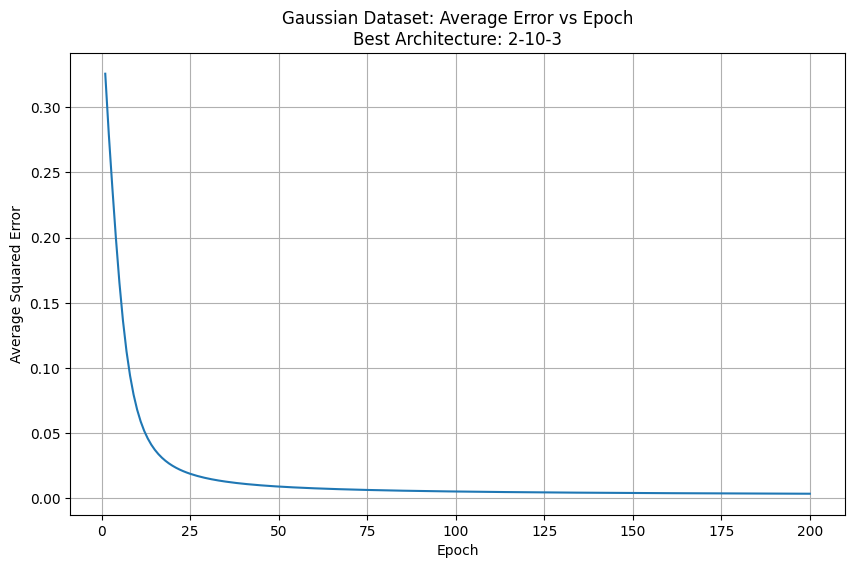

In [31]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    range(
        1,
        len(best_gaussian_history) + 1
    ),
    best_gaussian_history
)

plt.xlabel("Epoch")

plt.ylabel(
    "Average Squared Error"
)

plt.title(
    f"Gaussian Dataset: Average Error vs Epoch\n"
    f"Best Architecture: "
    f"2-{best_hidden_nodes}-3"
)

plt.grid(True)

plt.show()

In [33]:
def create_confusion_matrix(
    y_true,
    y_pred,
    num_classes=3
):

    matrix = np.zeros(
        (
            num_classes,
            num_classes
        ),
        dtype=int
    )

    for actual, predicted in zip(
        y_true,
        y_pred
    ):

        matrix[
            actual,
            predicted
        ] += 1

    return matrix

In [34]:
def plot_confusion_matrix(
    matrix,
    title
):

    plt.figure(
        figsize=(6, 5)
    )

    plt.imshow(
        matrix,
        interpolation="nearest"
    )

    plt.title(title)

    plt.colorbar()

    class_names = [
        "Class 0",
        "Class 1",
        "Class 2"
    ]

    plt.xticks(
        range(3),
        class_names
    )

    plt.yticks(
        range(3),
        class_names
    )

    plt.xlabel(
        "Predicted Class"
    )

    plt.ylabel(
        "Actual Class"
    )

    # Display numbers
    for i in range(3):

        for j in range(3):

            plt.text(
                j,
                i,
                str(
                    matrix[i, j]
                ),
                ha="center",
                va="center"
            )

    plt.tight_layout()

    plt.show()


Architecture: 2-3-3
Validation Accuracy: 100.00%
Confusion Matrix:
[[100   0   0]
 [  0 100   0]
 [  0   0 100]]


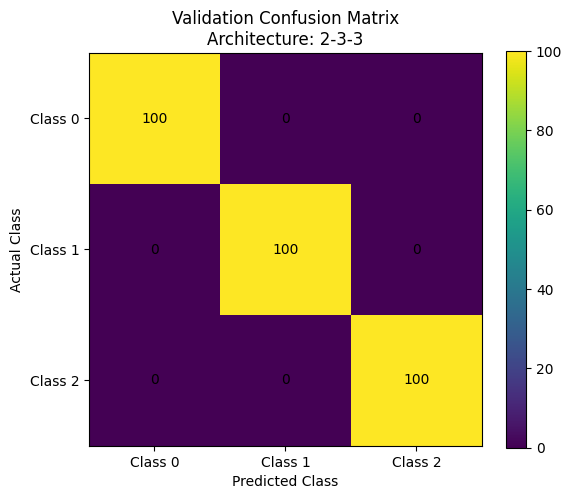


Architecture: 2-5-3
Validation Accuracy: 100.00%
Confusion Matrix:
[[100   0   0]
 [  0 100   0]
 [  0   0 100]]


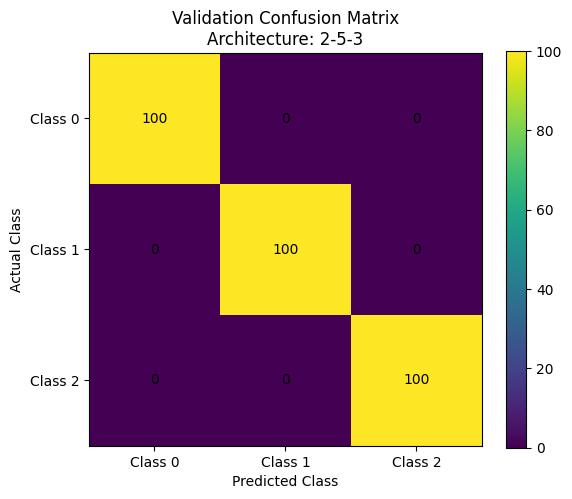


Architecture: 2-8-3
Validation Accuracy: 100.00%
Confusion Matrix:
[[100   0   0]
 [  0 100   0]
 [  0   0 100]]


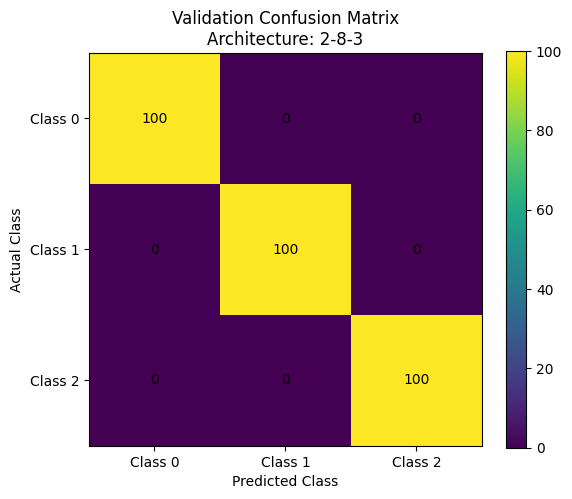


Architecture: 2-10-3
Validation Accuracy: 100.00%
Confusion Matrix:
[[100   0   0]
 [  0 100   0]
 [  0   0 100]]


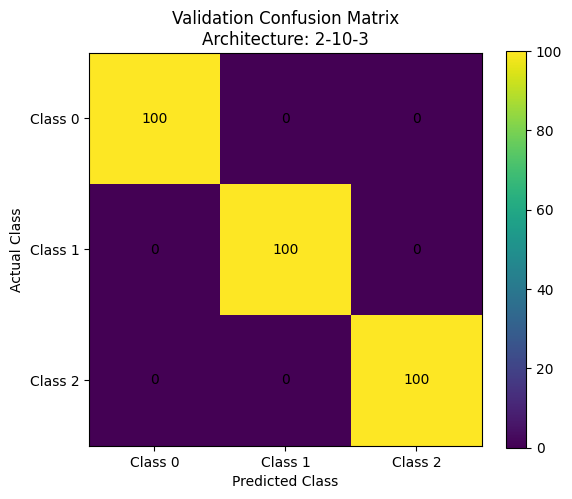

In [35]:
validation_results_all = []

for hidden_nodes in hidden_node_options:

    model = (
        trained_gaussian_models[
            hidden_nodes
        ]
    )

    # Predict validation data
    y_pred = model.predict(
        X_val_gaussian_normalized
    )

    # Accuracy
    accuracy = np.mean(
        y_pred
        == y_val_gaussian
    )

    # Confusion matrix
    cm = create_confusion_matrix(
        y_val_gaussian,
        y_pred
    )

    print(
        "\n"
        + "=" * 50
    )

    print(
        f"Architecture: "
        f"2-{hidden_nodes}-3"
    )

    print(
        f"Validation Accuracy: "
        f"{accuracy * 100:.2f}%"
    )

    print(
        "Confusion Matrix:"
    )

    print(cm)

    plot_confusion_matrix(
        cm,
        title=(
            f"Validation Confusion Matrix\n"
            f"Architecture: "
            f"2-{hidden_nodes}-3"
        )
    )

In [36]:
# Predict test data
y_test_pred_gaussian = (
    best_gaussian_model.predict(
        X_test_gaussian_normalized
    )
)

# Test accuracy
test_accuracy_gaussian = (
    np.mean(
        y_test_pred_gaussian
        == y_test_gaussian
    )
)

print(
    f"Best Architecture: "
    f"2-{best_hidden_nodes}-3"
)

print(
    f"Test Accuracy: "
    f"{test_accuracy_gaussian * 100:.2f}%"
)

Best Architecture: 2-10-3
Test Accuracy: 100.00%


Test Confusion Matrix:
[[100   0   0]
 [  0 100   0]
 [  0   0 100]]


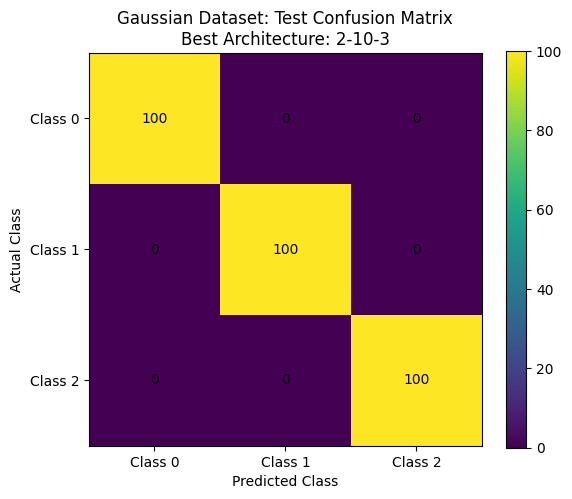

In [37]:
test_cm_gaussian = (
    create_confusion_matrix(
        y_test_gaussian,
        y_test_pred_gaussian
    )
)

print(
    "Test Confusion Matrix:"
)

print(
    test_cm_gaussian
)

plot_confusion_matrix(
    test_cm_gaussian,
    title=(
        "Gaussian Dataset: "
        "Test Confusion Matrix\n"
        f"Best Architecture: "
        f"2-{best_hidden_nodes}-3"
    )
)

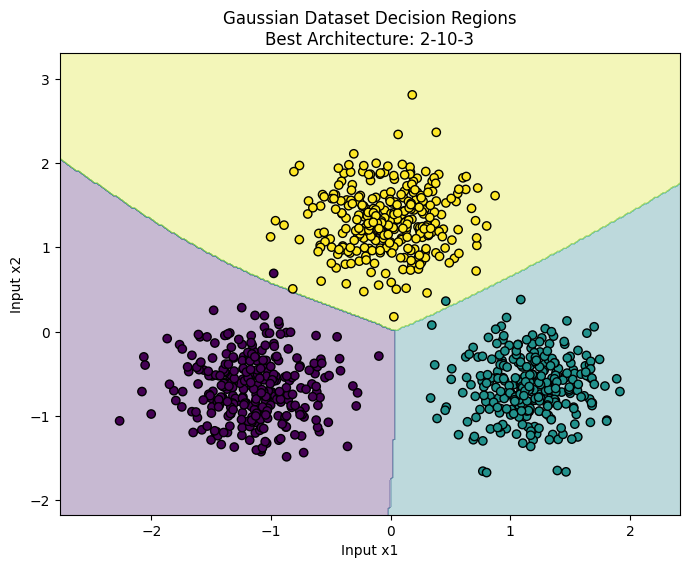

In [38]:
def plot_decision_regions(
    model,
    X,
    y,
    title
):

    # Define graph boundaries
    x_min = (
        X[:, 0].min() - 0.5
    )

    x_max = (
        X[:, 0].max() + 0.5
    )

    y_min = (
        X[:, 1].min() - 0.5
    )

    y_max = (
        X[:, 1].max() + 0.5
    )

    # Create mesh grid
    xx, yy = np.meshgrid(

        np.linspace(
            x_min,
            x_max,
            300
        ),

        np.linspace(
            y_min,
            y_max,
            300
        )
    )

    # Create grid points
    grid = np.c_[
        xx.ravel(),
        yy.ravel()
    ]

    # Predict classes
    predictions = model.predict(
        grid
    )

    predictions = predictions.reshape(
        xx.shape
    )

    # Plot decision regions
    plt.figure(
        figsize=(8, 6)
    )

    plt.contourf(
        xx,
        yy,
        predictions,
        alpha=0.3
    )

    # Plot training data
    plt.scatter(
        X[:, 0],
        X[:, 1],
        c=y,
        edgecolor="k"
    )

    plt.xlabel("Input x1")

    plt.ylabel("Input x2")

    plt.title(title)

    plt.show()
plot_decision_regions(
    best_gaussian_model,
    X_train_gaussian_normalized,
    y_train_gaussian,
    title=(
        "Gaussian Dataset Decision Regions\n"
        f"Best Architecture: "
        f"2-{best_hidden_nodes}-3"
    )
)

In [39]:
def get_node_outputs_one_hidden(
    model,
    X
):

    hidden_outputs = []
    output_outputs = []

    for x in X:

        # Forward pass
        model.forward(x)

        hidden_outputs.append(
            model.hidden_output.copy()
        )

        output_outputs.append(
            model.output.copy()
        )

    return (
        np.array(hidden_outputs),
        np.array(output_outputs)
    )

In [40]:
from mpl_toolkits.mplot3d import Axes3D

In [41]:
def plot_node_outputs_3d(
    X,
    node_outputs,
    layer_name,
    dataset_name
):

    number_of_nodes = (
        node_outputs.shape[1]
    )

    for node_index in range(
        number_of_nodes
    ):

        fig = plt.figure(
            figsize=(8, 6)
        )

        ax = fig.add_subplot(
            111,
            projection="3d"
        )

        ax.scatter(
            X[:, 0],
            X[:, 1],
            node_outputs[
                :,
                node_index
            ]
        )

        ax.set_xlabel(
            "Input x1"
        )

        ax.set_ylabel(
            "Input x2"
        )

        ax.set_zlabel(
            "Node Output"
        )

        ax.set_title(
            f"{dataset_name}\n"
            f"{layer_name} "
            f"Node {node_index + 1}"
        )

        plt.show()

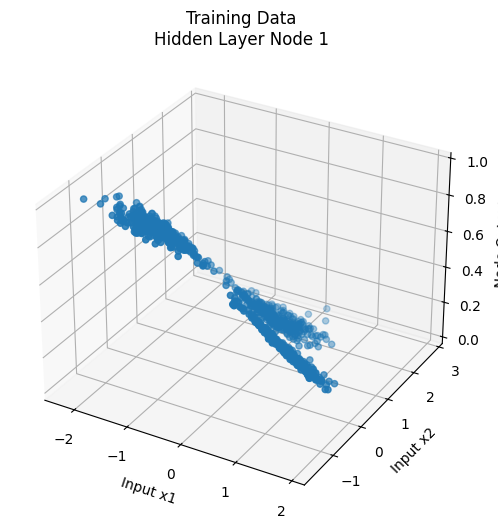

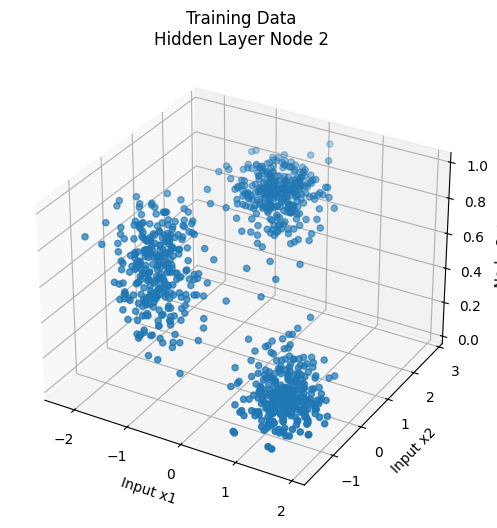

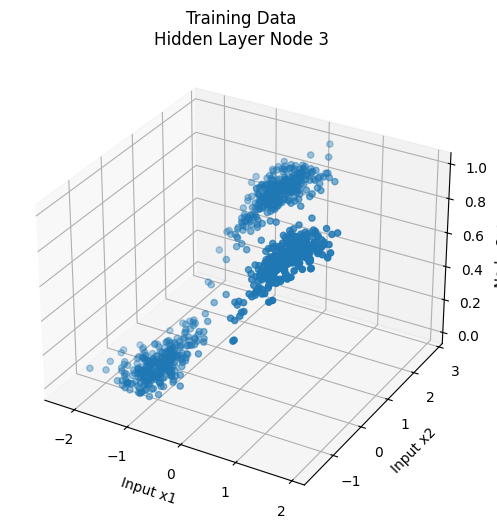

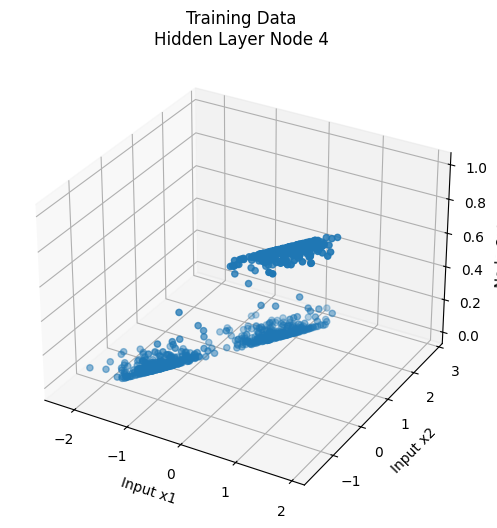

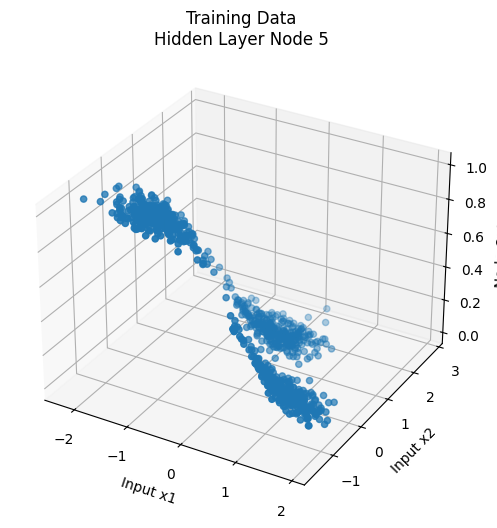

...

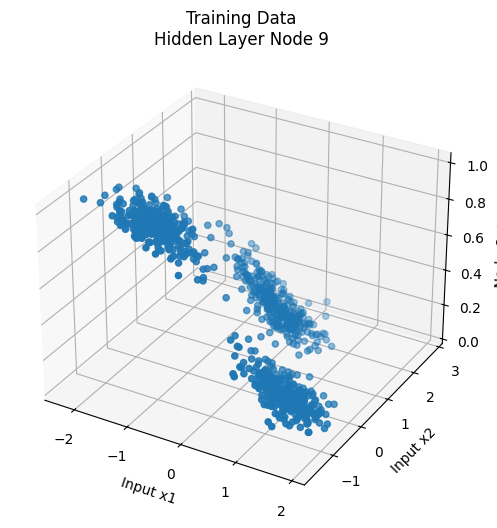

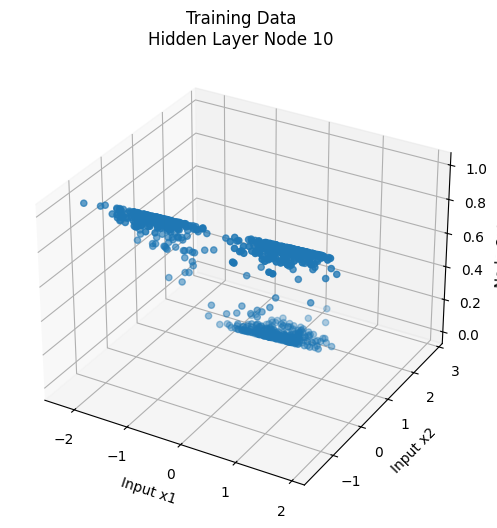

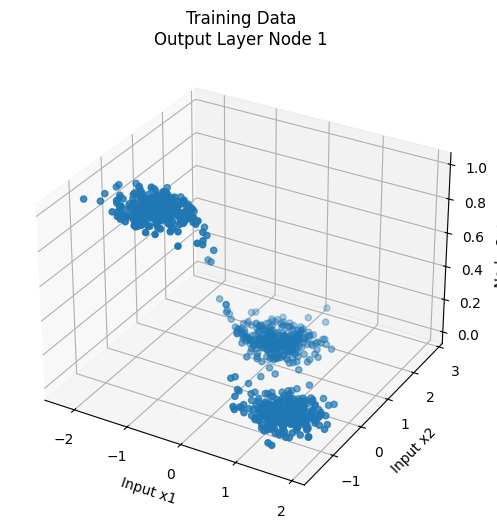

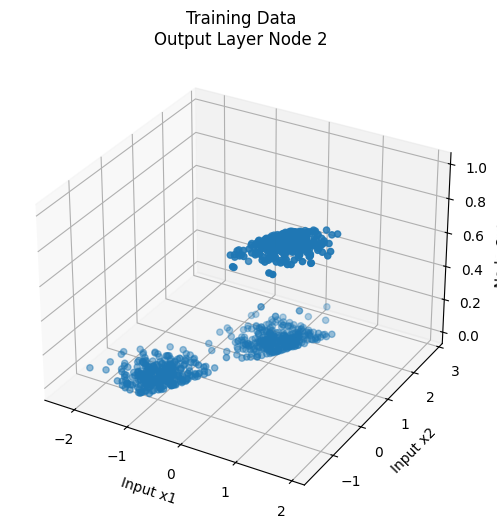

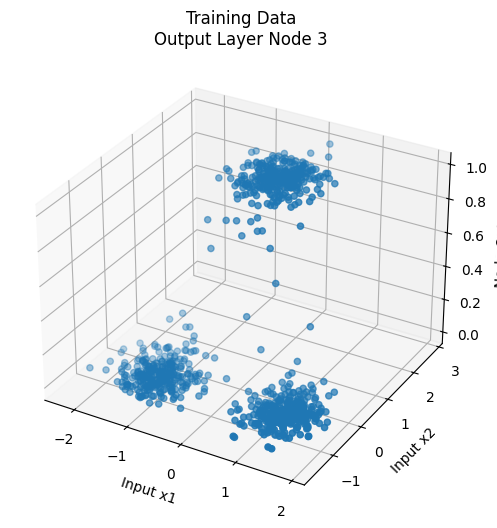

In [42]:
(
    hidden_train,
    output_train
) = get_node_outputs_one_hidden(
    best_gaussian_model,
    X_train_gaussian_normalized
)

plot_node_outputs_3d(
    X_train_gaussian_normalized,
    hidden_train,
    layer_name="Hidden Layer",
    dataset_name="Training Data"
)

plot_node_outputs_3d(
    X_train_gaussian_normalized,
    output_train,
    layer_name="Output Layer",
    dataset_name="Training Data"
)

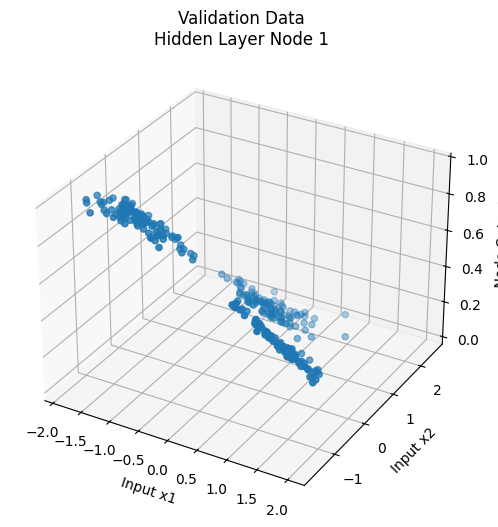

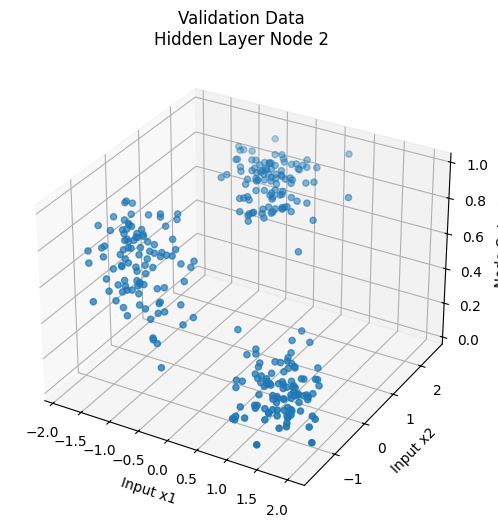

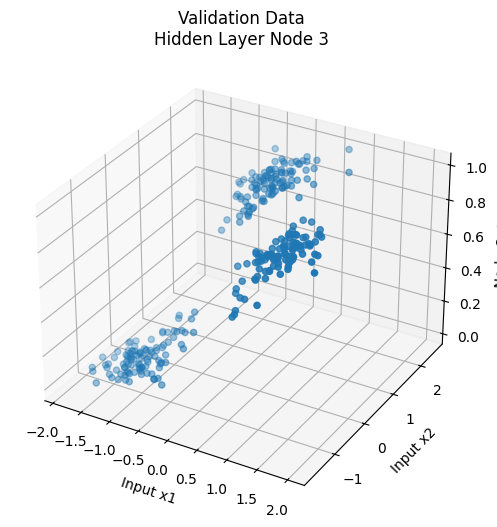

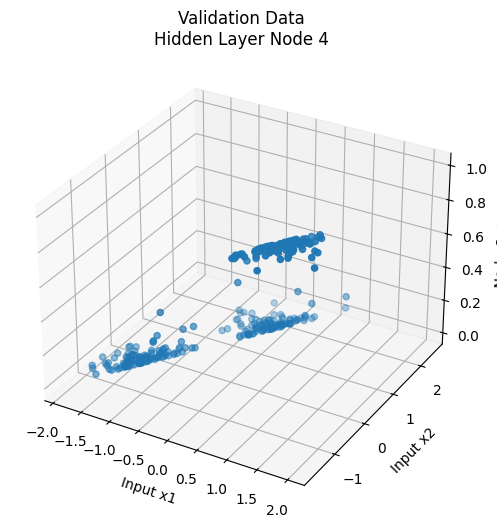

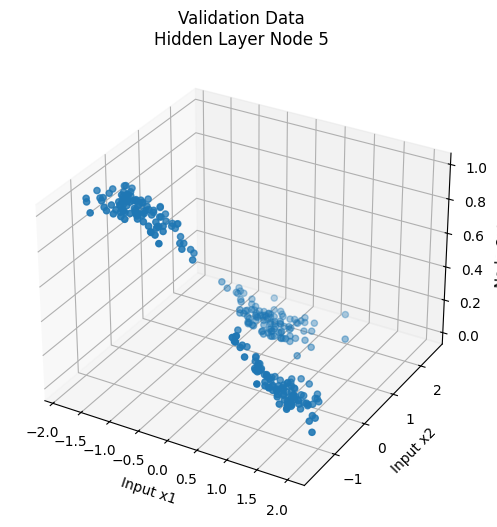

...

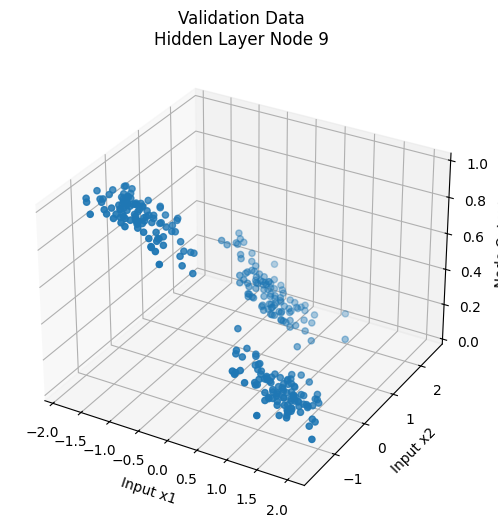

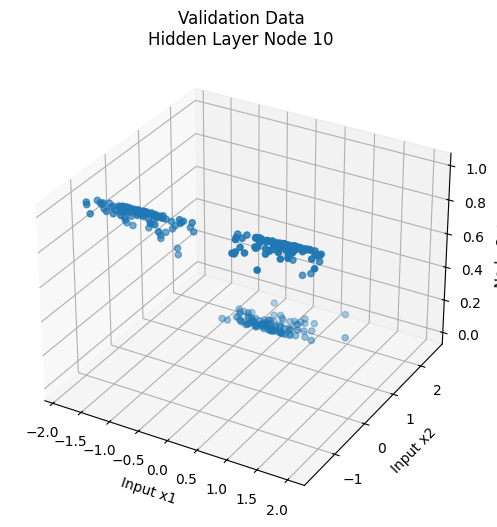

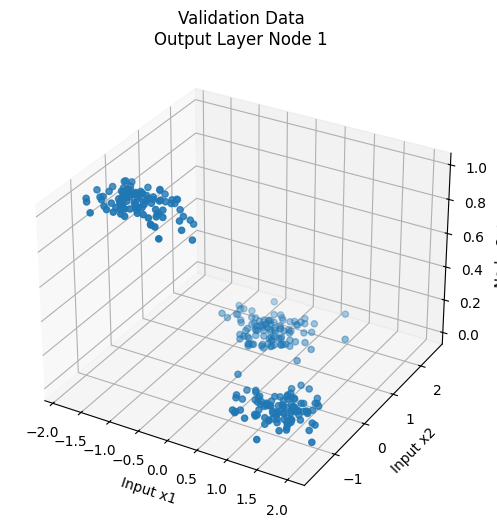

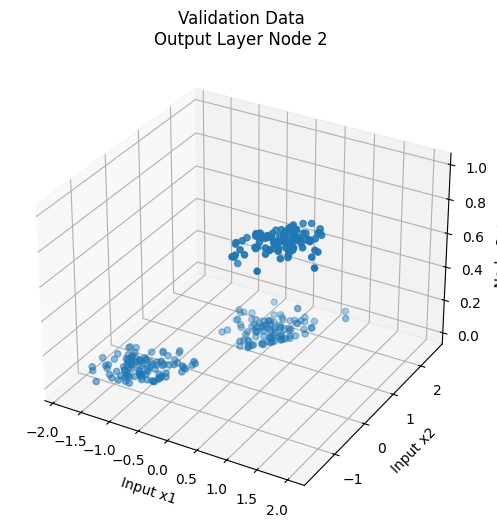

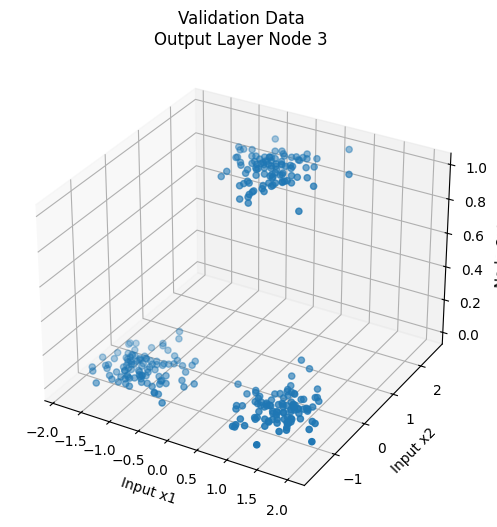

In [43]:
(
    hidden_val,
    output_val
) = get_node_outputs_one_hidden(
    best_gaussian_model,
    X_val_gaussian_normalized
)

plot_node_outputs_3d(
    X_val_gaussian_normalized,
    hidden_val,
    layer_name="Hidden Layer",
    dataset_name="Validation Data"
)

plot_node_outputs_3d(
    X_val_gaussian_normalized,
    output_val,
    layer_name="Output Layer",
    dataset_name="Validation Data"
)

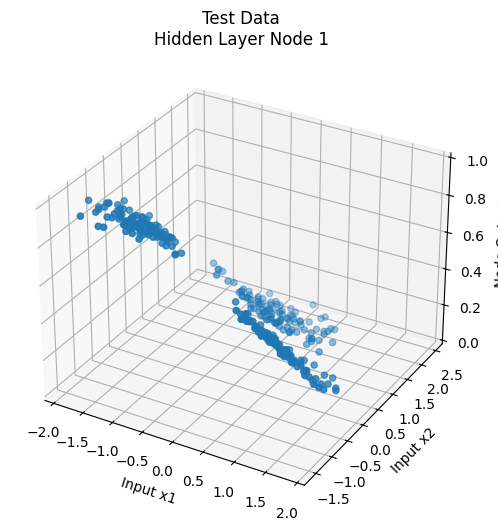

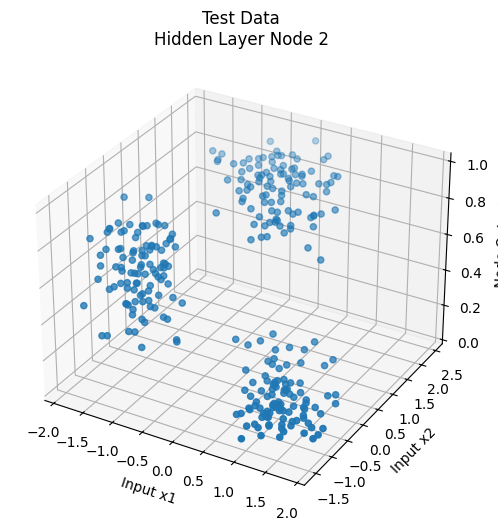

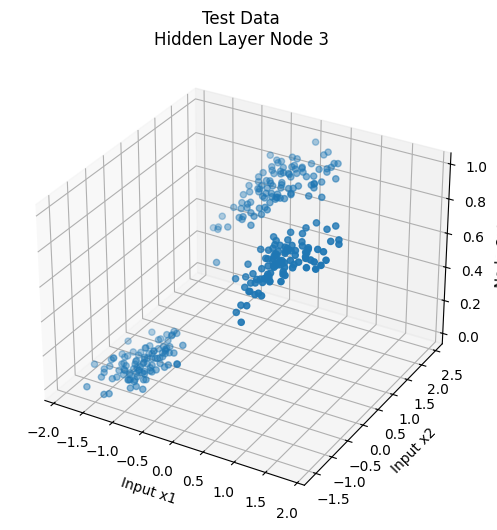

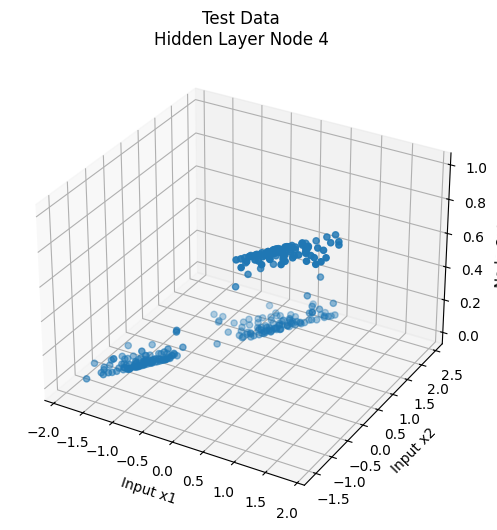

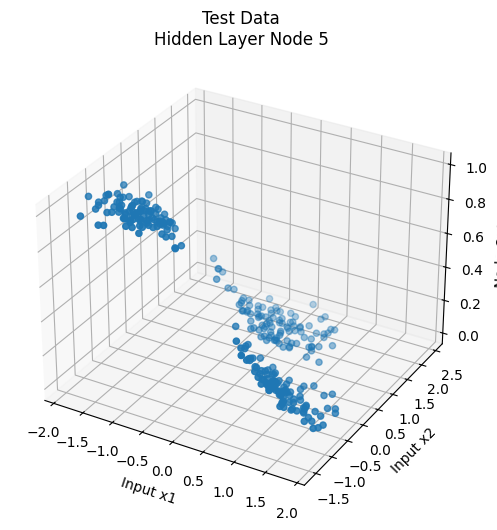

...

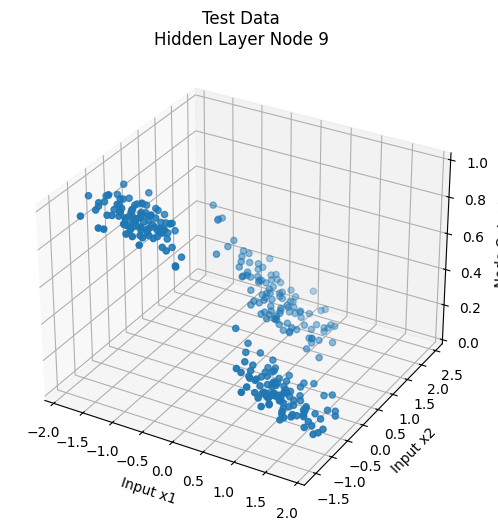

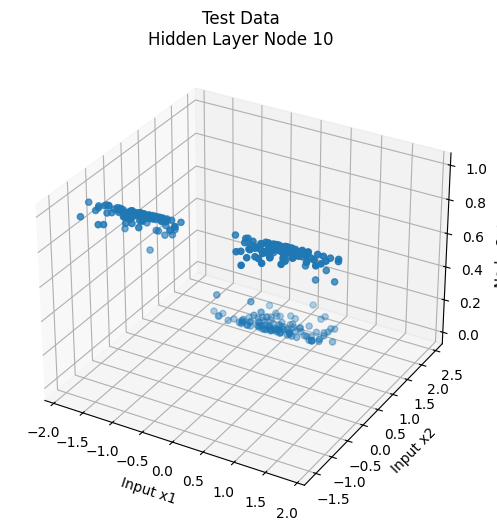

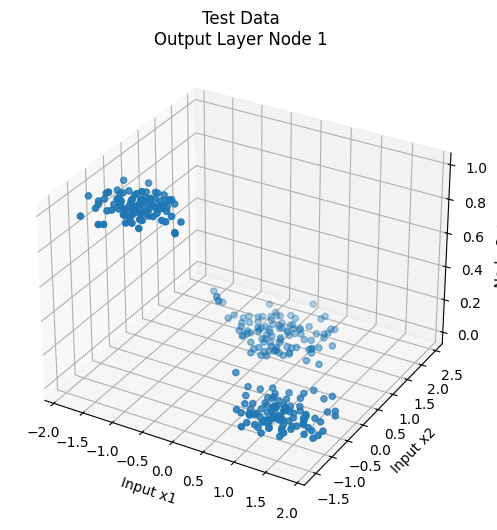

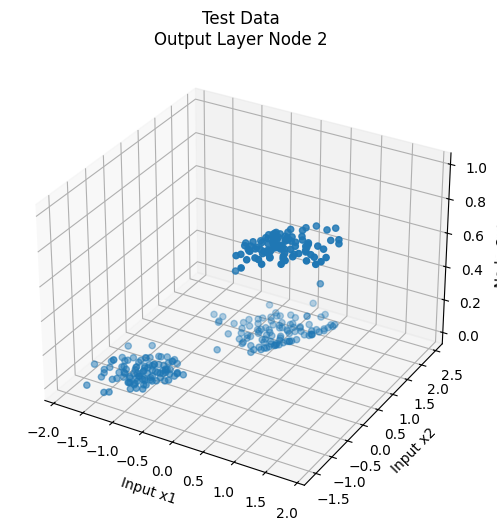

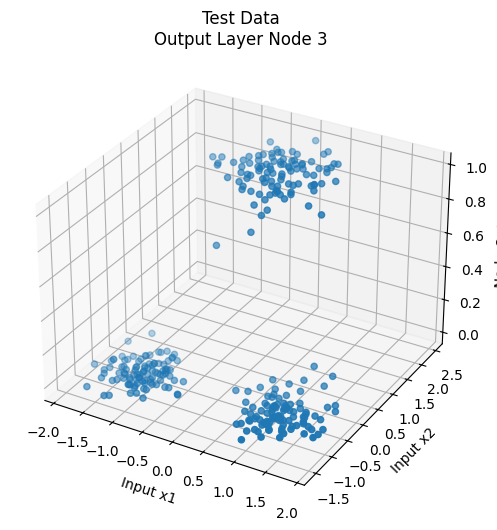

In [44]:
(
    hidden_test,
    output_test
) = get_node_outputs_one_hidden(
    best_gaussian_model,
    X_test_gaussian_normalized
)

plot_node_outputs_3d(
    X_test_gaussian_normalized,
    hidden_test,
    layer_name="Hidden Layer",
    dataset_name="Test Data"
)

plot_node_outputs_3d(
    X_test_gaussian_normalized,
    output_test,
    layer_name="Output Layer",
    dataset_name="Test Data"
)

In [45]:
def generate_spiral_data(
    samples_per_class=500,
    noise=0.2,
    random_seed=42
):

    np.random.seed(
        random_seed
    )

    total_samples = (
        samples_per_class
        * 3
    )

    X = np.zeros(
        (
            total_samples,
            2
        )
    )

    y = np.zeros(
        total_samples,
        dtype=int
    )

    for class_number in range(3):

        start = (
            class_number
            * samples_per_class
        )

        end = (
            (class_number + 1)
            * samples_per_class
        )

        radius = np.linspace(
            0,
            1,
            samples_per_class
        )

        angle = np.linspace(
            class_number
            * 4,

            (class_number + 1)
            * 4,

            samples_per_class
        )

        angle += (
            np.random.randn(
                samples_per_class
            )
            * noise
        )

        X[start:end, 0] = (
            radius
            * np.sin(
                angle
            )
        )

        X[start:end, 1] = (
            radius
            * np.cos(
                angle
            )
        )

        y[start:end] = (
            class_number
        )

    return X, y

In [46]:
X_spiral, y_spiral = (
    generate_spiral_data(
        samples_per_class=500
    )
)

print(
    X_spiral.shape
)

print(
    y_spiral.shape
)

(1500, 2)
(1500,)


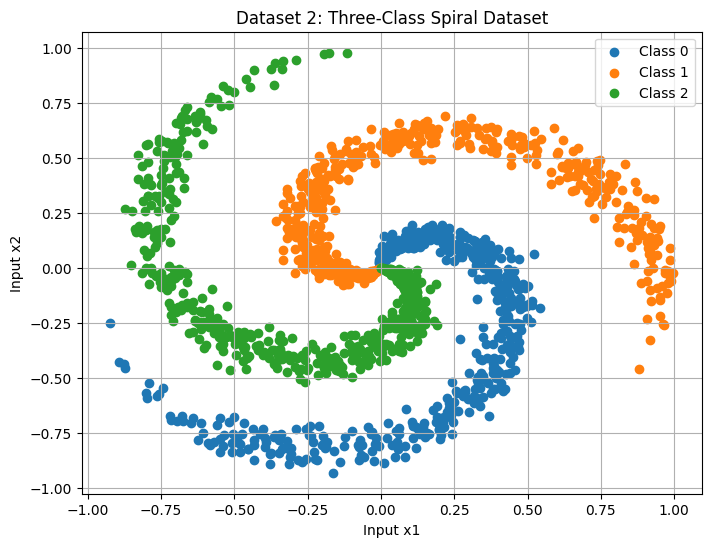

In [ ]:
plt.figure(
    figsize=(8, 6)
)

for class_number in range(3):

    plt.scatter(

        X_spiral[
            y_spiral == class_number,
            0
        ],

        X_spiral[
            y_spiral == class_number,
            1
        ],

        label=(
            f"Class {class_number}"
        )
    )

plt.xlabel(
    "Input x1"
)

plt.ylabel(
    "Input x2"
)

plt.title(
    "Dataset 2: "
    "Three-Class Spiral Dataset"
)

plt.legend()

plt.grid(True)

plt.show()

In [ ]:
(
    X_train_spiral,
    X_val_spiral,
    X_test_spiral,
    y_train_spiral,
    y_val_spiral,
    y_test_spiral
) = split_data_per_class(
    X_spiral,
    y_spiral
)

In [ ]:
spiral_mean = np.mean(
    X_train_spiral,
    axis=0
)

spiral_std = np.std(
    X_train_spiral,
    axis=0
)

X_train_spiral_normalized = (
    X_train_spiral
    - spiral_mean
) / spiral_std

X_val_spiral_normalized = (
    X_val_spiral
    - spiral_mean
) / spiral_std

X_test_spiral_normalized = (
    X_test_spiral
    - spiral_mean
) / spiral_std

In [ ]:
y_train_spiral_onehot = (
    one_hot_encode(
        y_train_spiral
    )
)

y_val_spiral_onehot = (
    one_hot_encode(
        y_val_spiral
    )
)

y_test_spiral_onehot = (
    one_hot_encode(
        y_test_spiral
    )
)

In [ ]:
class FCNN_TwoHiddenLayers:

    def __init__(
        self,
        input_size,
        hidden_size_1,
        hidden_size_2,
        output_size,
        random_seed=42
    ):

        np.random.seed(
            random_seed
        )

        # Input -> Hidden 1
        self.W1 = (
            np.random.randn(
                input_size,
                hidden_size_1
            )
            * np.sqrt(
                1 / input_size
            )
        )

        self.b1 = np.zeros(
            hidden_size_1
        )

        # Hidden 1 -> Hidden 2
        self.W2 = (
            np.random.randn(
                hidden_size_1,
                hidden_size_2
            )
            * np.sqrt(
                1
                / hidden_size_1
            )
        )

        self.b2 = np.zeros(
            hidden_size_2
        )

        # Hidden 2 -> Output
        self.W3 = (
            np.random.randn(
                hidden_size_2,
                output_size
            )
            * np.sqrt(
                1
                / hidden_size_2
            )
        )

        self.b3 = np.zeros(
            output_size
        )


    def forward(
        self,
        x
    ):

        # Hidden Layer 1
        self.z1 = (
            np.dot(
                x,
                self.W1
            )
            + self.b1
        )

        self.h1 = sigmoid(
            self.z1
        )

        # Hidden Layer 2
        self.z2 = (
            np.dot(
                self.h1,
                self.W2
            )
            + self.b2
        )

        self.h2 = sigmoid(
            self.z2
        )

        # Output Layer
        self.z3 = (
            np.dot(
                self.h2,
                self.W3
            )
            + self.b3
        )

        self.output = sigmoid(
            self.z3
        )

        return self.output


    def backward(
        self,
        x,
        target,
        learning_rate
    ):

        # Output layer
        output_error = (
            self.output
            - target
        )

        output_delta = (
            output_error
            * sigmoid_derivative(
                self.output
            )
        )

        dW3 = np.outer(
            self.h2,
            output_delta
        )

        db3 = output_delta


        # Hidden layer 2
        hidden2_error = np.dot(
            self.W3,
            output_delta
        )

        hidden2_delta = (
            hidden2_error
            * sigmoid_derivative(
                self.h2
            )
        )

        dW2 = np.outer(
            self.h1,
            hidden2_delta
        )

        db2 = hidden2_delta


        # Hidden layer 1
        hidden1_error = np.dot(
            self.W2,
            hidden2_delta
        )

        hidden1_delta = (
            hidden1_error
            * sigmoid_derivative(
                self.h1
            )
        )

        dW1 = np.outer(
            x,
            hidden1_delta
        )

        db1 = hidden1_delta


        # Update weights
        self.W3 -= (
            learning_rate
            * dW3
        )

        self.b3 -= (
            learning_rate
            * db3
        )

        self.W2 -= (
            learning_rate
            * dW2
        )

        self.b2 -= (
            learning_rate
            * db2
        )

        self.W1 -= (
            learning_rate
            * dW1
        )

        self.b1 -= (
            learning_rate
            * db1
        )


    def train(
        self,
        X_train,
        y_train,
        learning_rate=0.01,
        epochs=500
    ):

        average_errors = []

        for epoch in range(epochs):

            total_error = 0

            indices = (
                np.random.permutation(
                    len(X_train)
                )
            )

            for i in indices:

                x = X_train[i]

                target = y_train[i]

                prediction = (
                    self.forward(
                        x
                    )
                )

                error = (
                    squared_error(
                        target,
                        prediction
                    )
                )

                total_error += error

                self.backward(
                    x,
                    target,
                    learning_rate
                )

            average_error = (
                total_error
                / len(X_train)
            )

            average_errors.append(
                average_error
            )

            if (
                epoch + 1
            ) % 50 == 0:

                print(
                    f"Epoch {epoch + 1}, "
                    f"Average Error: "
                    f"{average_error:.6f}"
                )

        return average_errors


    def predict(
        self,
        X
    ):

        predictions = []

        for x in X:

            output = (
                self.forward(
                    x
                )
            )

            predicted_class = (
                np.argmax(
                    output
                )
            )

            predictions.append(
                predicted_class
            )

        return np.array(
            predictions
        )

In [ ]:
spiral_architectures = [

    (5, 3),

    (8, 5),

    (10, 5),

    (10, 8)

]

spiral_results = []

trained_spiral_models = {}

spiral_histories = {}

learning_rate = 0.01

epochs = 500

In [ ]:
for hidden_1, hidden_2 in (
    spiral_architectures
):

    print(
        "\n"
        + "=" * 50
    )

    print(
        f"Architecture: "
        f"2-{hidden_1}-"
        f"{hidden_2}-3"
    )

    model = (
        FCNN_TwoHiddenLayers(

            input_size=2,

            hidden_size_1=hidden_1,

            hidden_size_2=hidden_2,

            output_size=3,

            random_seed=42
        )
    )

    history = model.train(

        X_train_spiral_normalized,

        y_train_spiral_onehot,

        learning_rate=learning_rate,

        epochs=epochs
    )

    # Validation prediction
    y_val_pred = (
        model.predict(
            X_val_spiral_normalized
        )
    )

    validation_accuracy = (
        np.mean(
            y_val_pred
            == y_val_spiral
        )
    )

    architecture_name = (
        f"2-{hidden_1}-"
        f"{hidden_2}-3"
    )

    spiral_results.append({

        "Architecture":
            architecture_name,

        "Hidden Layer 1":
            hidden_1,

        "Hidden Layer 2":
            hidden_2,

        "Validation Accuracy":
            validation_accuracy,

        "Final Average Error":
            history[-1]

    })

    trained_spiral_models[
        architecture_name
    ] = model

    spiral_histories[
        architecture_name
    ] = history


Architecture: 2-5-3-3
Epoch 50, Average Error: 0.264747
Epoch 100, Average Error: 0.230348
Epoch 150, Average Error: 0.182013
Epoch 200, Average Error: 0.147158
Epoch 250, Average Error: 0.125579
Epoch 300, Average Error: 0.101758
Epoch 350, Average Error: 0.075766
Epoch 400, Average Error: 0.059292
Epoch 450, Average Error: 0.050504
Epoch 500, Average Error: 0.045307

Architecture: 2-8-5-3
Epoch 50, Average Error: 0.264505
Epoch 100, Average Error: 0.225971
Epoch 150, Average Error: 0.163398
Epoch 200, Average Error: 0.098840
Epoch 250, Average Error: 0.063000
Epoch 300, Average Error: 0.047485
Epoch 350, Average Error: 0.039515
Epoch 400, Average Error: 0.034430
Epoch 450, Average Error: 0.030866
Epoch 500, Average Error: 0.028155

Architecture: 2-10-5-3
Epoch 50, Average Error: 0.240543
Epoch 100, Average Error: 0.203172
Epoch 150, Average Error: 0.143213
Epoch 200, Average Error: 0.087429
Epoch 250, Average Error: 0.059277
Epoch 300, Average Error: 0.047264
Epoch 350, Average Erro

In [ ]:
spiral_results_df = pd.DataFrame(
    spiral_results
)

spiral_results_df = (
    spiral_results_df
    .sort_values(
        by="Validation Accuracy",
        ascending=False
    )
)

display(
    spiral_results_df
)

,Architecture,Hidden Layer 1,Hidden Layer 2,Validation Accuracy,Final Average Error
3,2-10-8-3,10,8,0.970000,0.027944
0,2-5-3-3,5,3,0.966667,0.045307
1,2-8-5-3,8,5,0.966667,0.028155
2,2-10-5-3,10,5,0.963333,0.032461


In [ ]:
best_spiral_architecture = (
    spiral_results_df
    .iloc[0]["Architecture"]
)

print(
    "Best Spiral Architecture:",
    best_spiral_architecture
)

best_spiral_model = (
    trained_spiral_models[
        best_spiral_architecture
    ]
)

best_spiral_history = (
    spiral_histories[
        best_spiral_architecture
    ]
)

Best Spiral Architecture: 2-10-8-3


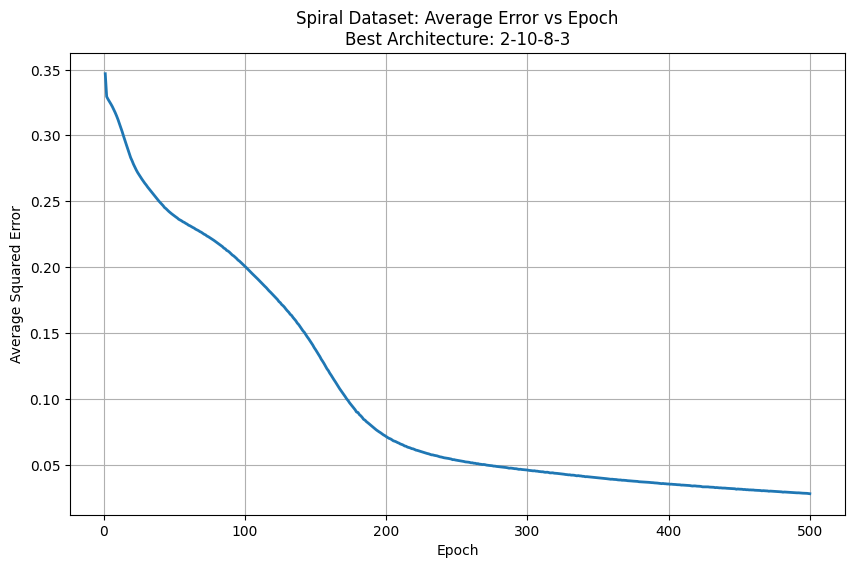

In [ ]:
plt.figure(
    figsize=(10, 6)
)

plt.plot(
    range(
        1,
        len(
            best_spiral_history
        ) + 1
    ),

    best_spiral_history,

    linewidth=2
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Average Squared Error"
)

plt.title(
    "Spiral Dataset: "
    "Average Error vs Epoch\n"
    f"Best Architecture: "
    f"{best_spiral_architecture}"
)

plt.grid(True)

plt.show()


Architecture: 2-5-3-3
Validation Accuracy: 96.67%
Confusion Matrix:
[[93  1  6]
 [ 2 98  0]
 [ 1  0 99]]


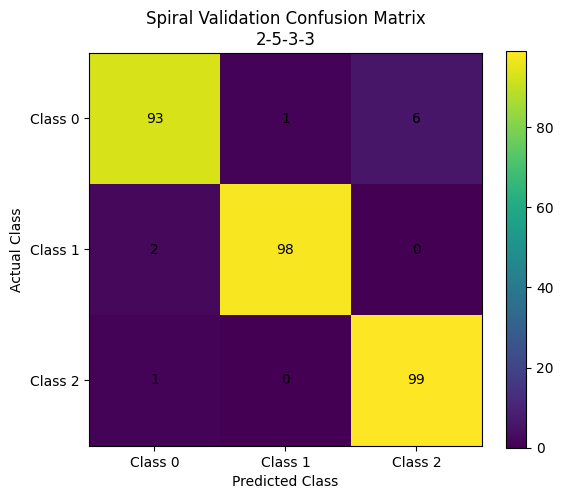


Architecture: 2-8-5-3
Validation Accuracy: 96.67%
Confusion Matrix:
[[100   0   0]
 [  1  96   3]
 [  0   6  94]]


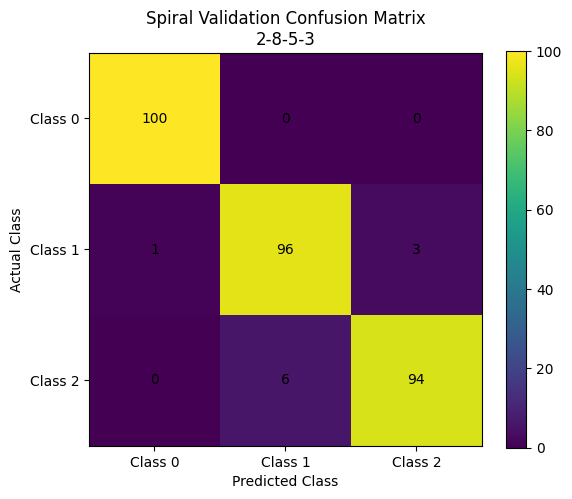


Architecture: 2-10-5-3
Validation Accuracy: 96.33%
Confusion Matrix:
[[96  1  3]
 [ 0 97  3]
 [ 0  4 96]]


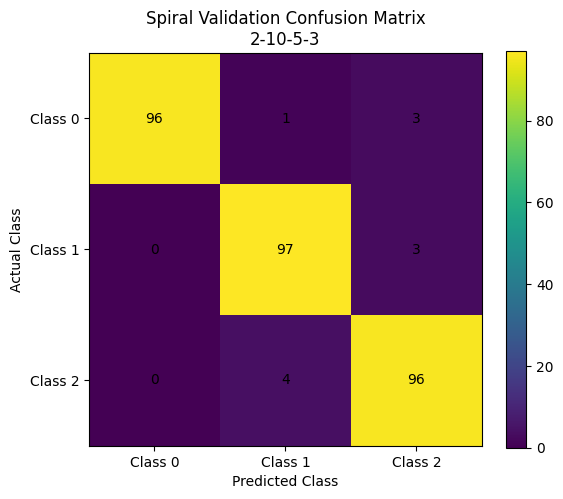


Architecture: 2-10-8-3
Validation Accuracy: 97.00%
Confusion Matrix:
[[98  1  1]
 [ 0 97  3]
 [ 3  1 96]]


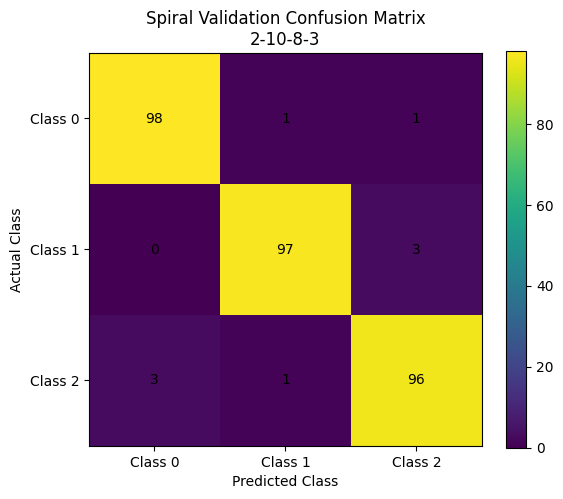

In [ ]:
for architecture_name, model in (
    trained_spiral_models.items()
):

    y_pred = model.predict(
        X_val_spiral_normalized
    )

    accuracy = np.mean(
        y_pred
        == y_val_spiral
    )

    cm = create_confusion_matrix(
        y_val_spiral,
        y_pred
    )

    print(
        "\n"
        + "=" * 50
    )

    print(
        f"Architecture: "
        f"{architecture_name}"
    )

    print(
        f"Validation Accuracy: "
        f"{accuracy * 100:.2f}%"
    )

    print(
        "Confusion Matrix:"
    )

    print(cm)

    plot_confusion_matrix(
        cm,

        title=(
            "Spiral Validation "
            "Confusion Matrix\n"
            f"{architecture_name}"
        )
    )

In [ ]:
y_test_pred_spiral = (
    best_spiral_model.predict(
        X_test_spiral_normalized
    )
)

test_accuracy_spiral = (
    np.mean(
        y_test_pred_spiral
        == y_test_spiral
    )
)

print(
    f"Best Architecture: "
    f"{best_spiral_architecture}"
)

print(
    f"Test Accuracy: "
    f"{test_accuracy_spiral * 100:.2f}%"
)

Best Architecture: 2-10-8-3
Test Accuracy: 97.67%


Test Confusion Matrix:
[[98  1  1]
 [ 0 99  1]
 [ 4  0 96]]


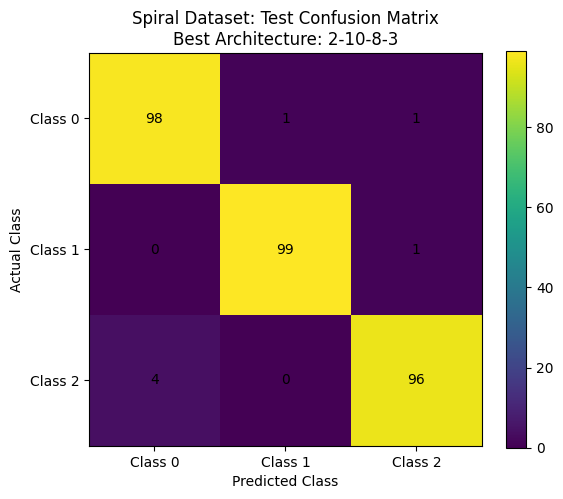

In [ ]:
test_cm_spiral = (
    create_confusion_matrix(
        y_test_spiral,
        y_test_pred_spiral
    )
)

print(
    "Test Confusion Matrix:"
)

print(
    test_cm_spiral
)

plot_confusion_matrix(

    test_cm_spiral,

    title=(
        "Spiral Dataset: "
        "Test Confusion Matrix\n"
        f"Best Architecture: "
        f"{best_spiral_architecture}"
    )
)

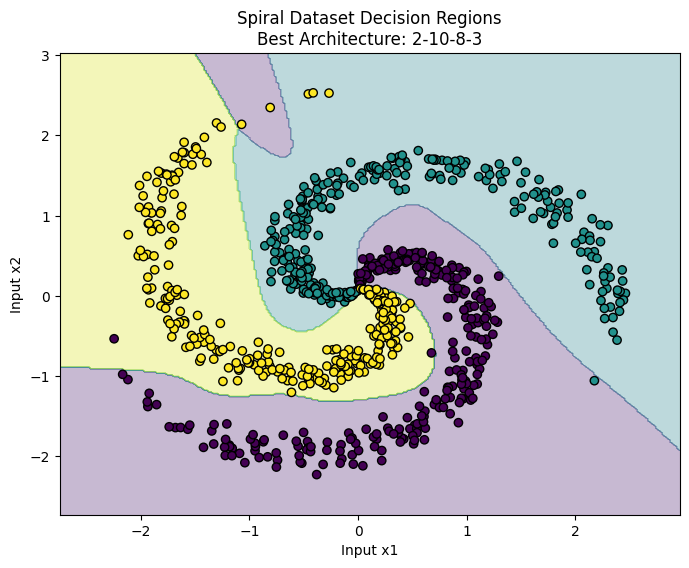

In [ ]:
plot_decision_regions(
    best_spiral_model,

    X_train_spiral_normalized,

    y_train_spiral,

    title=(
        "Spiral Dataset "
        "Decision Regions\n"
        f"Best Architecture: "
        f"{best_spiral_architecture}"
    )
)

In [ ]:
def get_node_outputs_two_hidden(
    model,
    X
):

    hidden_1_outputs = []

    hidden_2_outputs = []

    output_outputs = []

    for x in X:

        model.forward(
            x
        )

        hidden_1_outputs.append(
            model.h1.copy()
        )

        hidden_2_outputs.append(
            model.h2.copy()
        )

        output_outputs.append(
            model.output.copy()
        )

    return (

        np.array(
            hidden_1_outputs
        ),

        np.array(
            hidden_2_outputs
        ),

        np.array(
            output_outputs
        )
    )

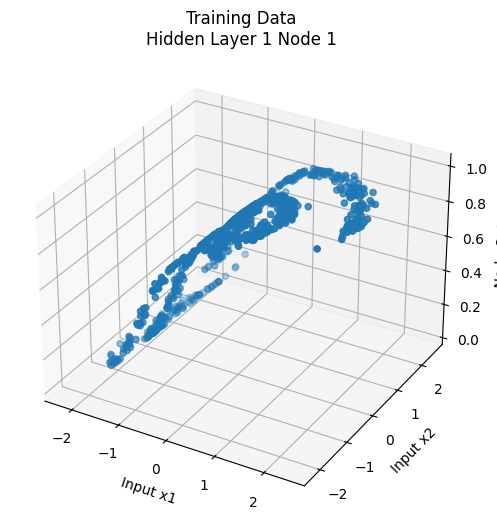

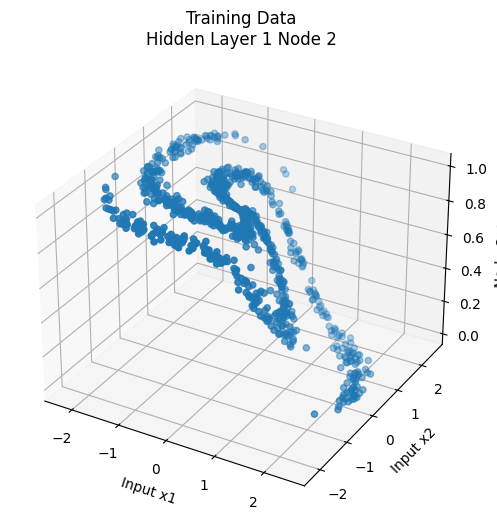

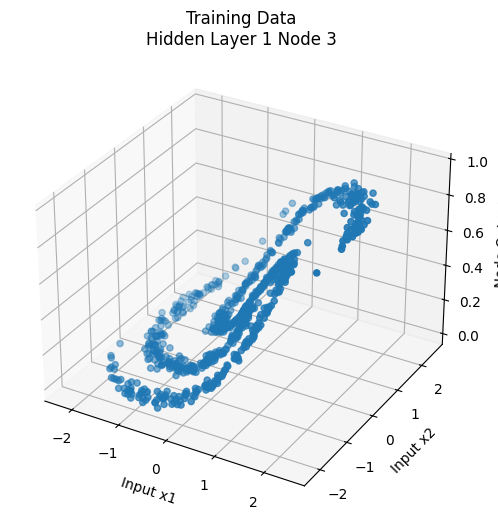

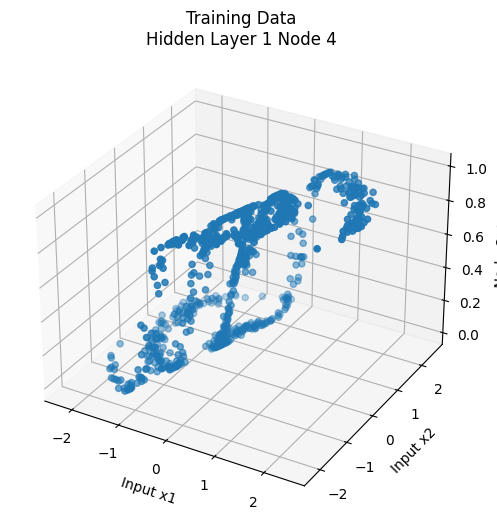

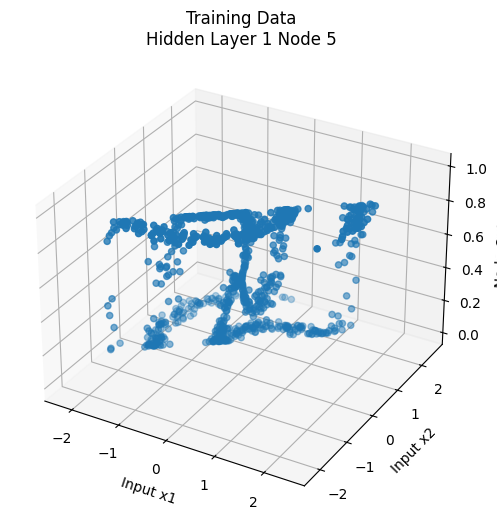

...

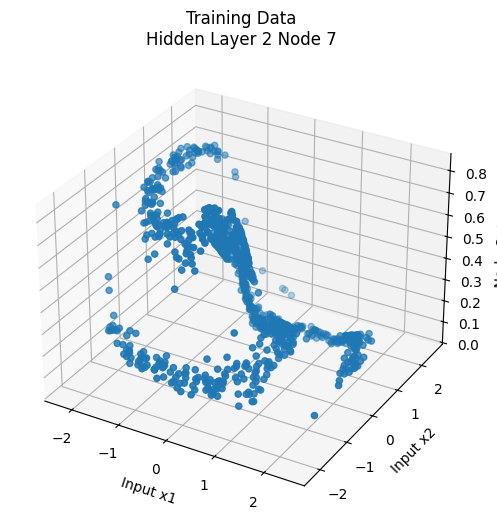

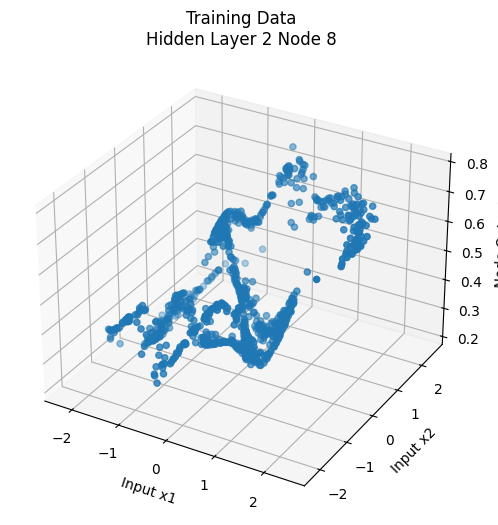

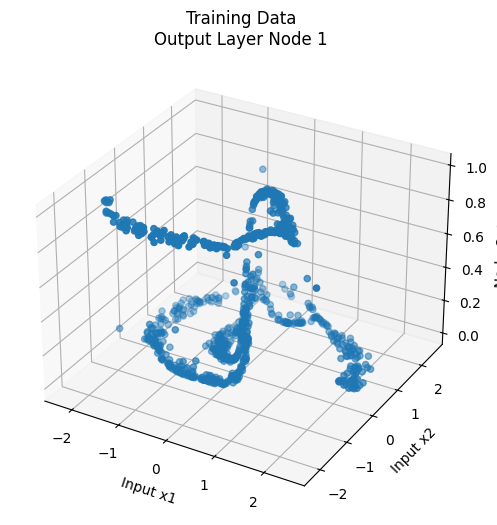

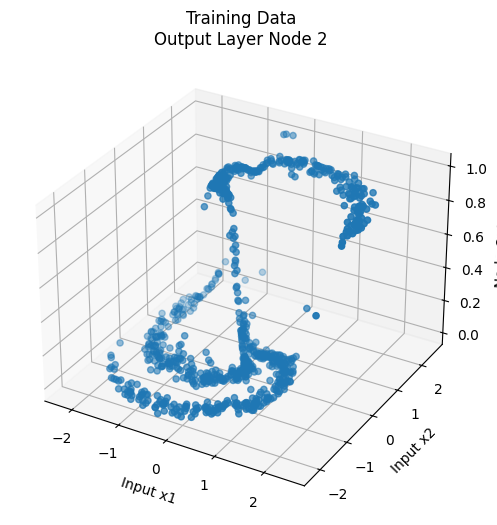

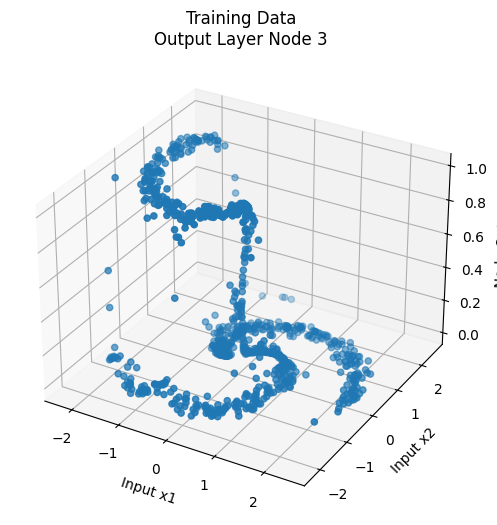

In [ ]:
(
    h1_train,
    h2_train,
    output_train
) = get_node_outputs_two_hidden(
    best_spiral_model,
    X_train_spiral_normalized
)

plot_node_outputs_3d(
    X_train_spiral_normalized,
    h1_train,
    layer_name="Hidden Layer 1",
    dataset_name="Training Data"
)

plot_node_outputs_3d(
    X_train_spiral_normalized,
    h2_train,
    layer_name="Hidden Layer 2",
    dataset_name="Training Data"
)

plot_node_outputs_3d(
    X_train_spiral_normalized,
    output_train,
    layer_name="Output Layer",
    dataset_name="Training Data"
)

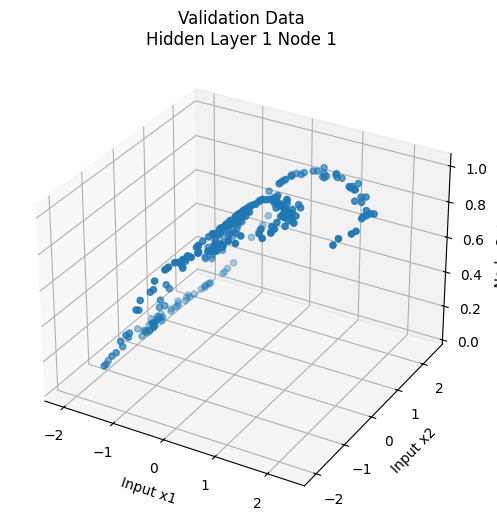

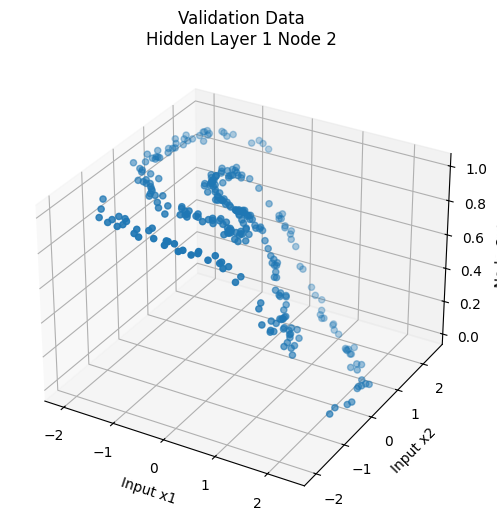

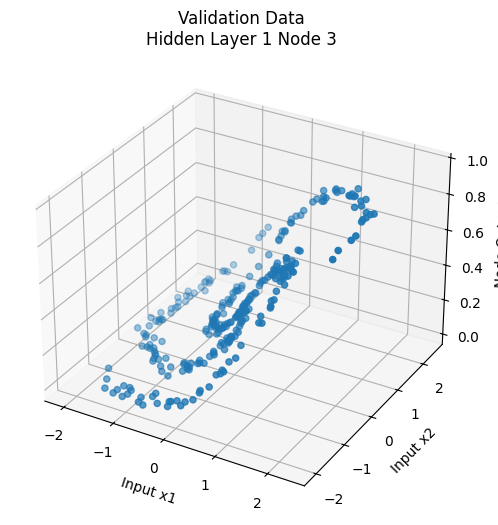

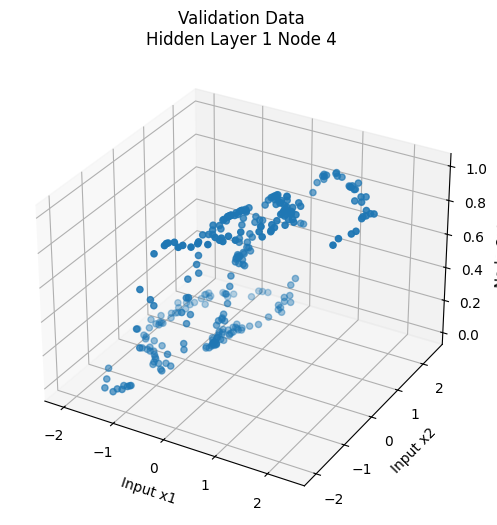

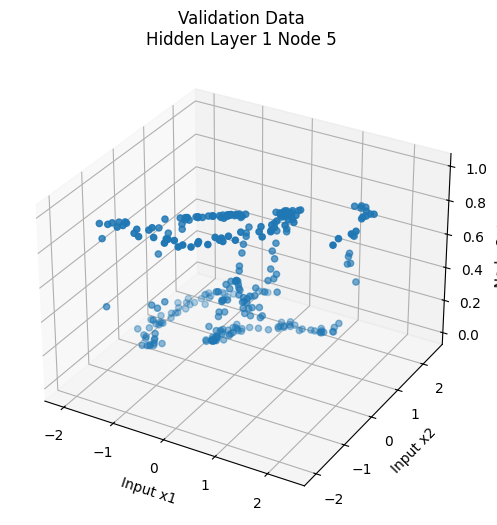

...

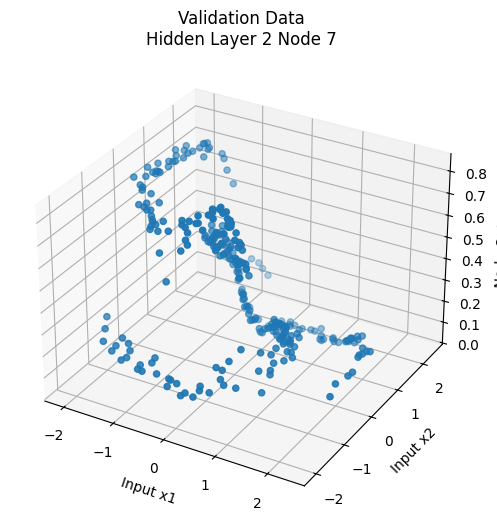

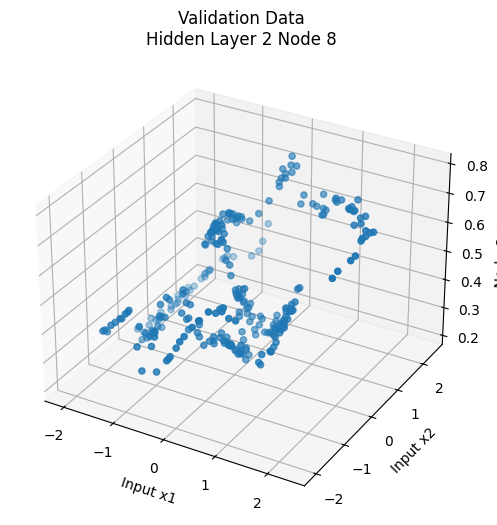

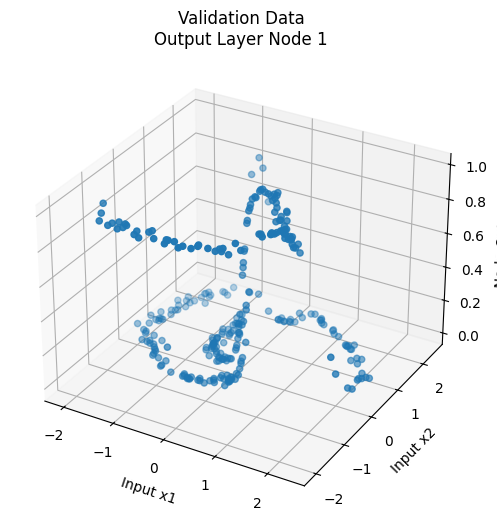

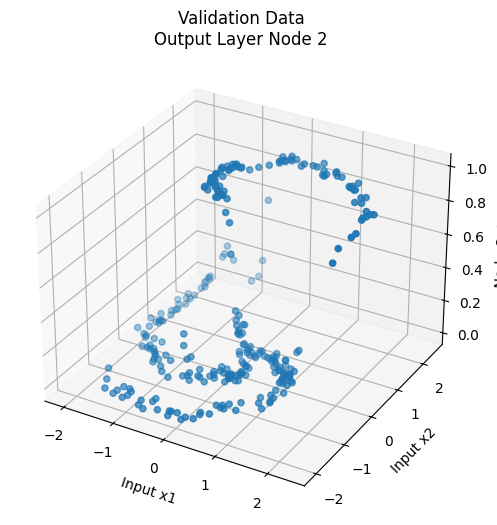

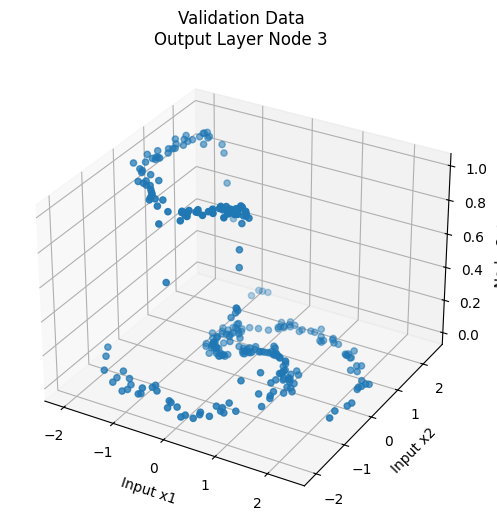

In [ ]:
(
    h1_val,
    h2_val,
    output_val
) = get_node_outputs_two_hidden(
    best_spiral_model,
    X_val_spiral_normalized
)

plot_node_outputs_3d(
    X_val_spiral_normalized,
    h1_val,
    layer_name="Hidden Layer 1",
    dataset_name="Validation Data"
)

plot_node_outputs_3d(
    X_val_spiral_normalized,
    h2_val,
    layer_name="Hidden Layer 2",
    dataset_name="Validation Data"
)

plot_node_outputs_3d(
    X_val_spiral_normalized,
    output_val,
    layer_name="Output Layer",
    dataset_name="Validation Data"
)

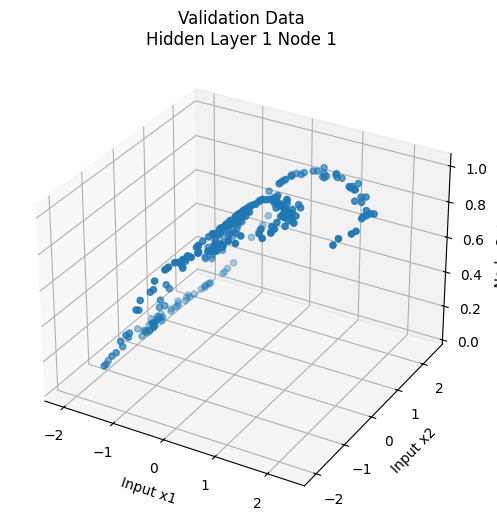

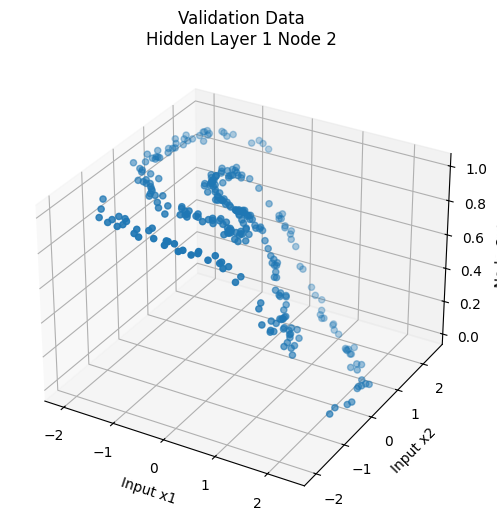

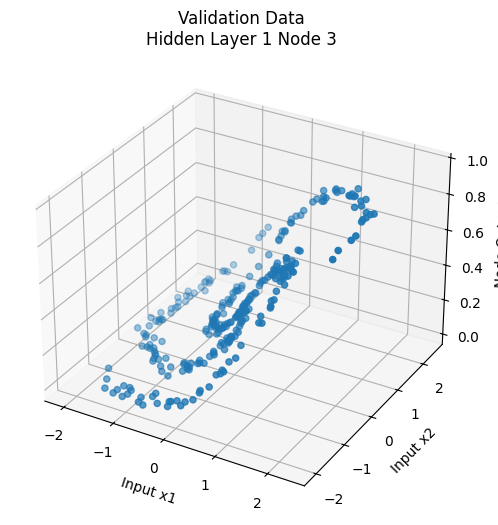

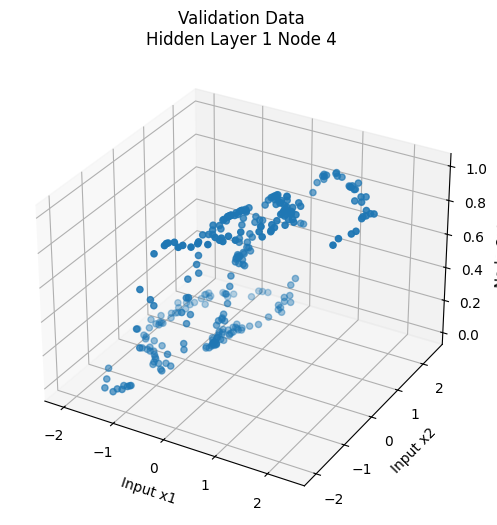

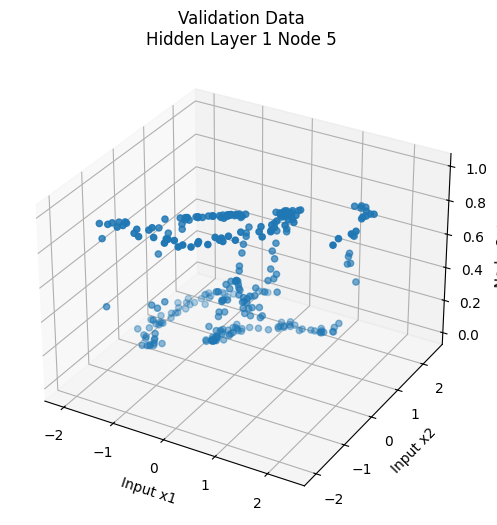

...

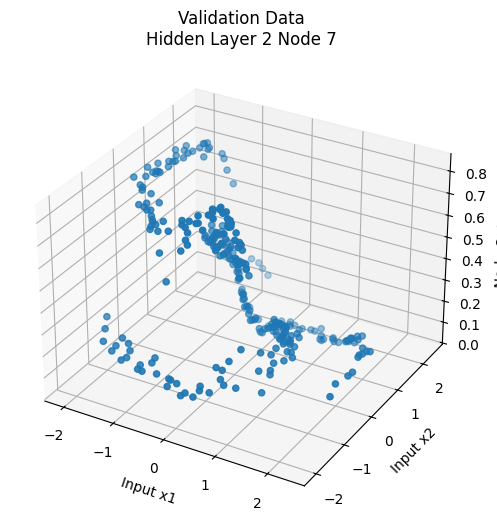

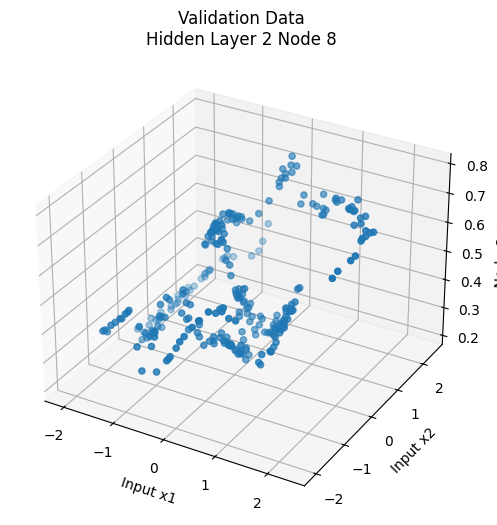

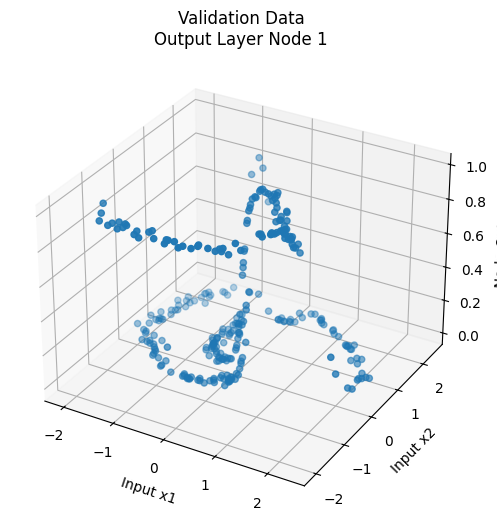

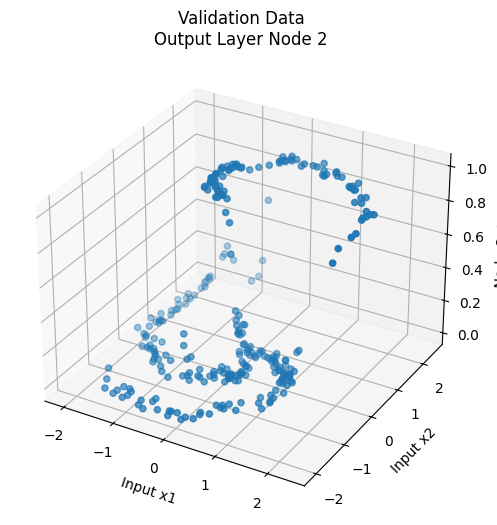

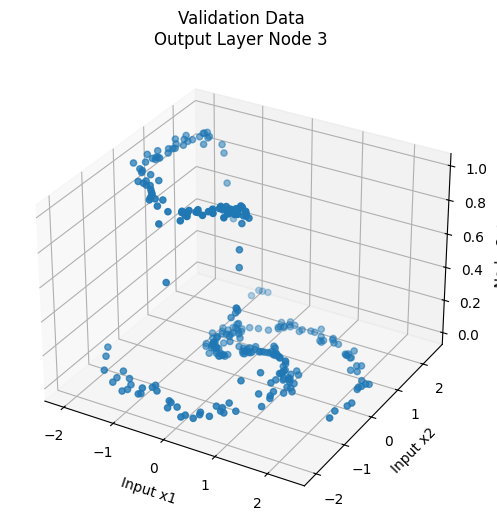

In [ ]:
(
    h1_val,
    h2_val,
    output_val
) = get_node_outputs_two_hidden(
    best_spiral_model,
    X_val_spiral_normalized
)

plot_node_outputs_3d(
    X_val_spiral_normalized,
    h1_val,
    layer_name="Hidden Layer 1",
    dataset_name="Validation Data"
)

plot_node_outputs_3d(
    X_val_spiral_normalized,
    h2_val,
    layer_name="Hidden Layer 2",
    dataset_name="Validation Data"
)

plot_node_outputs_3d(
    X_val_spiral_normalized,
    output_val,
    layer_name="Output Layer",
    dataset_name="Validation Data"
)

In [ ]:
class SingleNeuronModel:

    def __init__(
        self,
        input_size=2,
        output_size=3,
        random_seed=42
    ):

        np.random.seed(
            random_seed
        )

        self.W = (
            np.random.randn(
                input_size,
                output_size
            )
            * np.sqrt(
                1 / input_size
            )
        )

        self.b = np.zeros(
            output_size
        )


    def forward(
        self,
        x
    ):

        z = (
            np.dot(
                x,
                self.W
            )
            + self.b
        )

        self.output = sigmoid(
            z
        )

        return self.output


    def train(
        self,
        X_train,
        y_train,
        learning_rate=0.01,
        epochs=200
    ):

        history = []

        for epoch in range(
            epochs
        ):

            total_error = 0

            indices = (
                np.random.permutation(
                    len(X_train)
                )
            )

            for i in indices:

                x = X_train[i]

                target = y_train[i]

                prediction = (
                    self.forward(
                        x
                    )
                )

                error = (
                    squared_error(
                        target,
                        prediction
                    )
                )

                total_error += error

                output_delta = (
                    (
                        prediction
                        - target
                    )
                    * sigmoid_derivative(
                        prediction
                    )
                )

                dW = np.outer(
                    x,
                    output_delta
                )

                db = output_delta

                self.W -= (
                    learning_rate
                    * dW
                )

                self.b -= (
                    learning_rate
                    * db
                )

            average_error = (
                total_error
                / len(X_train)
            )

            history.append(
                average_error
            )

        return history


    def predict(
        self,
        X
    ):

        predictions = []

        for x in X:

            output = (
                self.forward(
                    x
                )
            )

            predictions.append(
                np.argmax(
                    output
                )
            )

        return np.array(
            predictions
        )

In [ ]:
single_gaussian_model = (
    SingleNeuronModel()
)

single_gaussian_history = (
    single_gaussian_model.train(

        X_train_gaussian_normalized,

        y_train_gaussian_onehot,

        learning_rate=0.01,

        epochs=200
    )
)

single_gaussian_pred = (
    single_gaussian_model.predict(
        X_test_gaussian_normalized
    )
)

single_gaussian_accuracy = (
    np.mean(
        single_gaussian_pred
        == y_test_gaussian
    )
)

print(
    f"Single Neuron Test Accuracy: "
    f"{single_gaussian_accuracy * 100:.2f}%"
)

print(
    f"Best FCNN Test Accuracy: "
    f"{test_accuracy_gaussian * 100:.2f}%"
)

Single Neuron Test Accuracy: 100.00%
Best FCNN Test Accuracy: 100.00%


In [ ]:
single_spiral_model = (
    SingleNeuronModel()
)

single_spiral_history = (
    single_spiral_model.train(

        X_train_spiral_normalized,

        y_train_spiral_onehot,

        learning_rate=0.01,

        epochs=500
    )
)

single_spiral_pred = (
    single_spiral_model.predict(
        X_test_spiral_normalized
    )
)

single_spiral_accuracy = (
    np.mean(
        single_spiral_pred
        == y_test_spiral
    )
)

print(
    f"Single Neuron Test Accuracy: "
    f"{single_spiral_accuracy * 100:.2f}%"
)

print(
    f"Best FCNN Test Accuracy: "
    f"{test_accuracy_spiral * 100:.2f}%"
)

Single Neuron Test Accuracy: 57.67%
Best FCNN Test Accuracy: 97.67%
